# BOI Investors' Guidebook (2022) — PDF Extraction & Chunking Pipeline

This notebook extracts, cleans, structures, and chunks text and tables from the **Board of Investments (BOI) Investors' Guidebook (2022)** to prepare structured records (`chunks.jsonl`) for a Retrieval-Augmented Generation (RAG) chatbot.

## Pipeline Overview
- **Week 1:** PDF page loading, text cleaning (de-hyphenation, page headers/footers, layout quirks), and initial inspection.
- **Week 2:** Table of Contents (TOC) parsing, structural assignment (`chapter`, `agency`, `procedure`), block/table extraction, chunking experiments, chunk sampling, and `chunks.jsonl` export.

## Cell 1: Setup

In [36]:
!pip -q install pypdf pymupdf pdfplumber sentence-transformers
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [37]:
# Pin the versions used in this run. Add faiss-cpu, rank-bm25 and gradio here once Week 3 and 4 install them.
!pip freeze | grep -iE "^(pypdf|pymupdf|pdfplumber|sentence-transformers)==" > /content/drive/MyDrive/AI3-Project/requirements.txt
!cat /content/drive/MyDrive/AI3-Project/requirements.txt

pdfplumber==0.11.11
pymupdf==2.1
pypdf==7.1.1
sentence-transformers==5.7.0


## Cell 2: Config
One place for every path. Change `BASE` to match your Drive folder.

In [38]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/AI3-Project")
RAW = BASE / "data/raw"
RAW_PDF = RAW / "2022-Investors-Guidebook-as-of-06-June-2022.pdf"
PROCESSED = BASE / "data/processed"
LOGS = BASE / "logs"

for p in (RAW, PROCESSED, LOGS):
    p.mkdir(parents=True, exist_ok=True)

assert RAW_PDF.exists(), "PDF not found: put it in AI3-Project/data/raw/ on Drive"
print("OK:", RAW_PDF)

DEFAULT_MAX_CHARS = 1000
DEFAULT_OVERLAP = 150
CHUNK_SIZES = (600, 800, 1000, 1500)

OK: /content/drive/MyDrive/AI3-Project/data/raw/2022-Investors-Guidebook-as-of-06-June-2022.pdf


## Cell 3: Extract raw pages (Day 2)

In [39]:
from pypdf import PdfReader

def extract_pages(pdf_path):
    """Return a list with one dict per page: {"pdf_page": int, "raw_text": str}."""
    # pdf_page starts at 1 (pypdf counts from 0); extract_text() can return None, so fall back to ""
    reader = PdfReader(str(pdf_path))
    extracted = []
    for idx, page in enumerate(reader.pages, start=1):
        text = page.extract_text()
        extracted.append({
            "pdf_page": idx,
            "raw_text": text if text is not None else ""
        })
    return extracted

pages = extract_pages(RAW_PDF)
print(len(pages))                     # expected: 502
print(pages[11]["pdf_page"])          # expected: 12

502
12


## Cell 4: Inspect the raw text (Day 2)

In [40]:
def show(page_no, n=1500):
    """Print the first n characters of the raw text of PDF page `page_no` (1-based)."""
    # repr() shows hidden newlines and odd spaces that print() hides
    pg = pages[page_no - 1]
    text = pg["raw_text"]
    print(f"=== PDF Page {pg['pdf_page']} (len={len(text)}) ===")
    print(repr(text[:300]))
    print(text[:n])
    print("-" * 60)

for p in [1, 2, 3, 4, 11, 12, 80, 101, 119, 300, 500]:
    show(p)

=== PDF Page 1 (len=210) ===
'G/F Industry and Investments Building, 385   www.boi.gov.ph \nSen. Gil Puyat Avenue, Makati City 1200, Philippines  www.boi-own.gov.ph \nTel No.: (+63 02) 897 6682   \n \n  \nINVESTORS’ \nGUIDEBOOK 2022 \n      \n    \n'
G/F Industry and Investments Building, 385   www.boi.gov.ph 
Sen. Gil Puyat Avenue, Makati City 1200, Philippines  www.boi-own.gov.ph 
Tel No.: (+63 02) 897 6682   
 
  
INVESTORS’ 
GUIDEBOOK 2022 
      
    

------------------------------------------------------------
=== PDF Page 2 (len=1630) ===
' \nNavigate to General Business Procedures  \n \ni INTRODUCTION \nINTRODUCTION \n \nWith the ASEAN Integration and aggressive campaign of the Philippine Government to attract \ninvestments by capitalizing on the ease of doing business in the country, more foreign \ninvestors are considering the Philippines '
 
Navigate to General Business Procedures  
 
i INTRODUCTION 
INTRODUCTION 
 
With the ASEAN Integration and aggressive campaign of the 

In [41]:
from collections import Counter

# 1. Most common FIRST non-empty line across all pages (expected: the "Navigate to..." line, 500 times)
first_lines = Counter()
for pg in pages:
    non_empty = [line.strip() for line in pg["raw_text"].splitlines() if line.strip()]
    if non_empty:
        first_lines[non_empty[0]] += 1

most_common_first, most_common_count = first_lines.most_common(1)[0]
print("Most common first line:", repr(most_common_first), "-> count:", most_common_count)

# 2. Pages containing "END OF TRANSACTION" (expected: 137)
eot_pages = [pg["pdf_page"] for pg in pages if "END OF TRANSACTION" in pg["raw_text"]]
print("Pages with 'END OF TRANSACTION':", len(eot_pages))

# 3. Total characters of all raw text (expected: about 969,000)
total_raw_chars = sum(len(pg["raw_text"]) for pg in pages)
print("Total raw characters:", total_raw_chars)

Most common first line: 'Navigate to General Business Procedures' -> count: 500
Pages with 'END OF TRANSACTION': 137
Total raw characters: 968686


- **Line-end hyphens:** `fix_hyphenation` matches **55** `word-\nword` cases in this run (pypdf 7.1.1). The count can differ by a few between pypdf versions, because versions extract the spaces at line ends differently, so we report the number from our own run. Only the line break is removed and the hyphen is kept, which preserves real hyphenated words like `non-immigrant` and `e-tablet`.


## Cell 5: Compare extractors (Day 3)

In [42]:
import time, fitz, pdfplumber      # fitz is PyMuPDF

def with_pypdf(pdf_path, page_no):
    reader = PdfReader(str(pdf_path))
    return reader.pages[page_no - 1].extract_text() or ""

def with_pymupdf(pdf_path, page_no):
    doc = fitz.open(str(pdf_path))
    try:
        return doc[page_no - 1].get_text("text", sort=True)
    finally:
        doc.close()

def with_pdfplumber(pdf_path, page_no):
    with pdfplumber.open(str(pdf_path)) as pdf:
        return pdf.pages[page_no - 1].extract_text() or ""

def pdfplumber_tables(pdf_path, page_no):
    with pdfplumber.open(str(pdf_path)) as pdf:
        return pdf.pages[page_no - 1].extract_tables()

def pymupdf_tables(pdf_path, page_no):
    doc = fitz.open(str(pdf_path))
    try:
        tabs = doc[page_no - 1].find_tables()
        return [t.extract() for t in tabs.tables]
    finally:
        doc.close()

# Side-by-side comparison on prose (page 2) and tables (pages 119 and 300)
for p in [2, 119, 300]:
    print(f"================ PAGE {p} ================")
    print("--- pypdf ---")
    print(with_pypdf(RAW_PDF, p)[:600])
    print("--- PyMuPDF (sort=True) ---")
    print(with_pymupdf(RAW_PDF, p)[:600])
    print("--- pdfplumber text ---")
    print(with_pdfplumber(RAW_PDF, p)[:600])
    print("--- pdfplumber tables (first 2 rows) ---")
    for tbl in pdfplumber_tables(RAW_PDF, p):
        print(tbl[:2])
    print("--- PyMuPDF tables (first 2 rows) ---")
    for tbl in pymupdf_tables(RAW_PDF, p):
        print(tbl[:2])

# Timing across all pages (extrapolate ~30 pages for pdfplumber)
t0 = time.perf_counter()
reader = PdfReader(str(RAW_PDF))
_ = [pg.extract_text() or "" for pg in reader.pages]
print(f"pypdf all {len(reader.pages)} pages: {time.perf_counter() - t0:.2f}s")

t0 = time.perf_counter()
doc = fitz.open(str(RAW_PDF))
_ = [pg.get_text("text", sort=True) for pg in doc]
doc.close()
print(f"PyMuPDF all {len(pages)} pages: {time.perf_counter() - t0:.2f}s")

sample_n = 30
t0 = time.perf_counter()
with pdfplumber.open(str(RAW_PDF)) as pdf:
    _ = [pg.extract_text() or "" for pg in pdf.pages[:sample_n]]
elapsed_30 = time.perf_counter() - t0
print(f"pdfplumber {sample_n} pages: {elapsed_30:.2f}s -> extrapolated {len(pages)} pages: {elapsed_30 * (len(pages) / sample_n):.2f}s")

# Table-extraction timing (measured, 30 pages each, then extrapolated)
t0 = time.perf_counter()
with pdfplumber.open(str(RAW_PDF)) as pdf:
    _ = [pg.extract_tables() for pg in pdf.pages[:sample_n]]
el = time.perf_counter() - t0
print(f"pdfplumber extract_tables {sample_n} pages: {el:.2f}s -> extrapolated {len(pages)} pages: {el * len(pages) / sample_n:.2f}s")

t0 = time.perf_counter()
doc = fitz.open(str(RAW_PDF))
_ = [doc[i].find_tables() for i in range(sample_n)]
doc.close()
el = time.perf_counter() - t0
print(f"PyMuPDF find_tables {sample_n} pages: {el:.2f}s -> extrapolated {len(pages)} pages: {el * len(pages) / sample_n:.2f}s")


================ PAGE 2 ================
--- pypdf ---
 
Navigate to General Business Procedures  
 
i INTRODUCTION 
INTRODUCTION 
 
With the ASEAN Integration and aggressive campaign of the Philippine Government to attract 
investments by capitalizing on the ease of doing business in the country, more foreign 
investors are considering the Philippines as the most feasible site in the int ernational arena 
to establish their businesses. The Board of Investments (BOI), as the lead industry promotion 
agency in the country, signifies its commitment to further encourage the entry of investments 
through proactive initiatives and collaboration with va
--- PyMuPDF (sort=True) ---
                                                               INTRODUCTION     i

INTRODUCTION

    With the ASEAN Integration and aggressive campaign of the Philippine Government to attract
    investments by capitalizing on the ease of doing business in the country, more foreign
    investors are considering the

### Extractor comparison
| Criterion | pypdf | PyMuPDF | pdfplumber text | pdfplumber tables |
|---|---|---|---|---|
| Table rows readable (a step's cells together)? | No — columns are interleaved across separate lines | Partial — `sort=True` preserves visual column spacing with wide gaps | Partial — keeps horizontal row alignment better than `pypdf`, though multi-line cells still wrap across lines | Yes — returns structured 2D row/column cell lists |
| Reading order correct? | Good on prose, fragmented on tables | Good on both prose and visual table layout | Good on prose and row-level table order | Good within detected table grids |
| Words spaced correctly? | Mostly, with occasional mid-word split artifacts (e.g., `int ernational`, `bu siness`) | Clean spacing in plain text (`sort=True`), though `find_tables()` merges words without spaces | Clean, accurate word spacing | Clean, accurate word spacing inside cells |
| Time for all pages | 29.60s | 11.28s | ~79.75s (4.77s for 30 pages extrapolated) | See the table-timing lines in Cell 5 (measured on 30 pages, then extrapolated) |


**Decision and reason (2 sentences):** We keep `pypdf` for the Week 1 baseline so page counts and cleaning numbers stay consistent, but PyMuPDF was cleaner (no mid-word splits such as `"int ernational"` on p. 2 and `"non -resident"` on p. 13) and 2.6x faster (`11.28s` vs `29.60s`), so those splits are a known limitation of the current data and switching extractor is the recommended next step. For table-heavy pages in Week 2, we use pdfplumber table bounding boxes so step rows stay together.


### Methodology: which library does what
- **pypdf** reads the page text used for Week 1 cleaning. The cleaning rules also use it to parse the printed-page label and running-header title (`printed_page`, `section_title`) and to tag `page_type`. The Week 2 structure (TOC parsing and the `chapter` / `agency` / `procedure` assignment) works on this cleaned pypdf text.
- **pdfplumber** builds the Week 2 blocks (paragraphs, list items and table rows) and detects tables with `find_tables()`. Pages that contain tables are read with it, so each table row stays together and the text above and below the table keeps its reading order. Pages without tables reuse the pypdf `clean_text`, split into blocks.
- **PyMuPDF** was used only to compare extractors (Cell 5), to check the page count in W2-4 and to render page images for visual checks. It does not produce any chunk text.


## Cell 6: Cleaning rules (Days 4-5)
Each rule returns the new text **and** a count, so the cleaning log builds itself. Don't overwrite `raw_text`.

In [43]:
import re

def remove_footer(text):
    """Remove the 'Navigate to General Business Procedures' line.
    Return (new_text, lines_removed)."""
    pattern = re.compile(r"^[ \t]*Navigate to General Business Procedures[ \t]*\r?$", re.MULTILINE)
    new_text, count = pattern.subn("", text)
    return new_text, count

def parse_page_label(text):
    """Find the label on the first non-empty line, e.g. '100 REGISTRATION OF INWARD INVESTMENTS'.
    Return (new_text, printed_page, section_title). printed_page stays a STRING.
    Return (text, None, None) if the first line is not a label (pages 1 and 502)."""
    lines = text.splitlines(keepends=True)
    first_idx = None
    for i, line in enumerate(lines):
        if line.strip():
            first_idx = i
            break

    if first_idx is None:
        return text, None, None

    first_line_clean = lines[first_idx].strip()
    m = re.match(r"^(\d+|[ivxlcdmIVXLCDM]+)\s+([A-Z][A-Z0-9 /&(),.-]{2,})$", first_line_clean)
    if not m:
        return text, None, None

    printed_page = m.group(1)
    section_title = re.sub(r"\s+", " ", m.group(2)).strip()

    remaining_lines = lines[:first_idx] + lines[first_idx + 1:]
    new_text = "".join(remaining_lines)
    return new_text, printed_page, section_title

def fix_hyphenation(text):
    """Join 'word-\\nword' by removing only the line break. The hyphen stays,
    because nearly all of these are real hyphenated words (non-immigrant, e-mail)."""
    pattern = re.compile(r"([A-Za-z])-[ \t]*\r?\n[ \t]*([a-z])")
    new_text, count = pattern.subn(r"\1-\2", text)
    return new_text, count

def normalize_bullets(text):
    """Map bullet characters (•, ◦, \\uf0b7, ...) to one symbol. Return (new_text, changes)."""
    bullet_chars = ["•", "◦", "▪", "▫", "▸", "►", "‣", "∙", "\uf0b7", "\uf0a7", "\u2022", "\u25e6"]
    changes = 0
    out_chars = []
    for ch in text:
        if ch in bullet_chars:
            if ch != "•":
                changes += 1
            out_chars.append("•")
        else:
            out_chars.append(ch)
    return "".join(out_chars), changes

# Rule 6: quotes and dashes -> plain ASCII. Peso sign and ñ/Ñ are left alone.
QUOTE_DASH_MAP = {
    "\u2019": "'",   # ’
    "\u201c": '"',   # “
    "\u201d": '"',   # ”
    "\u2013": "-",   # –
}
_QD_TABLE = str.maketrans(QUOTE_DASH_MAP)

def normalize_quotes_dashes(text):
    """Return (new_text, number_of_characters_changed)."""
    changes = sum(1 for ch in text if ch in QUOTE_DASH_MAP)
    return text.translate(_QD_TABLE), changes

def collapse_whitespace(text):
    """Collapse repeated spaces and 3+ blank lines only. KEEP single newlines. Return (new_text, changes)."""
    changes = 0
    text_after_blanks, c1 = re.subn(r"(?:\r?\n[ \t]*){3,}", "\n\n", text)
    changes += c1
    text_after_spaces, c2 = re.subn(r"[ \t]{2,}", " ", text_after_blanks)
    changes += c2
    return text_after_spaces.strip(), changes

In [44]:
# Test each rule on 5 pages BEFORE running on everything.
# 2 = prose, 3 = divider, 12 = first content page, 119 = table, 502 = back cover
TEST_PAGES = [2, 3, 12, 119, 502]

for p_no in TEST_PAGES:
    raw_t = pages[p_no - 1]["raw_text"]
    print(f"================ TEST PAGE {p_no} ================")

    t1, n_foot = remove_footer(raw_t)
    t2, p_page, sec_title = parse_page_label(t1)
    t3, n_hyph = fix_hyphenation(t2)
    t4, n_bull = normalize_bullets(t3)
    t5, n_qd = normalize_quotes_dashes(t4)
    t6, n_ws = collapse_whitespace(t5)

    print(f"footer_removed={n_foot}, label=({p_page!r}, {sec_title!r}), "
          f"hyph={n_hyph}, bullets={n_bull}, quotes_dashes={n_qd}, ws={n_ws}")
    print("--- BEFORE (first 300 chars) ---")
    print(repr(raw_t[:300]))
    print("--- AFTER (first 300 chars) ---")
    print(repr(t6[:300]))

# Scratch check: list real line-end hyphen cases so you can see what the rule keeps
cases = []
for pg in pages:
    t, _ = remove_footer(pg["raw_text"])
    t, _, _ = parse_page_label(t)
    for m in re.finditer(r"[A-Za-z]-[ \t]*\r?\n[ \t]*[a-z]", t):
        cases.append((pg["pdf_page"], t[max(0, m.start()-15):m.end()+15]))
print("\nLine-end hyphen cases:", len(cases))
for c in cases[:10]:
    print(c)

================ TEST PAGE 2 ================
footer_removed=1, label=('i', 'INTRODUCTION'), hyph=0, bullets=0, quotes_dashes=1, ws=7
--- BEFORE (first 300 chars) ---
' \nNavigate to General Business Procedures  \n \ni INTRODUCTION \nINTRODUCTION \n \nWith the ASEAN Integration and aggressive campaign of the Philippine Government to attract \ninvestments by capitalizing on the ease of doing business in the country, more foreign \ninvestors are considering the Philippines '
--- AFTER (first 300 chars) ---
'INTRODUCTION \n \nWith the ASEAN Integration and aggressive campaign of the Philippine Government to attract \ninvestments by capitalizing on the ease of doing business in the country, more foreign \ninvestors are considering the Philippines as the most feasible site in the int ernational arena \nto esta'
================ TEST PAGE 3 ================
footer_removed=1, label=('ii', 'GENERAL BUSINESS PROCEDURE'), hyph=0, bullets=0, quotes_dashes=0, ws=2
--- BEFORE (first 300 chars) ---


## Cell 7: Page types

In [45]:
PAGE_TYPES = [
    "cover", "front_matter", "toc", "divider",
    "section_heading", "content", "directory",
    "back_cover", "blank_or_image"
]

def tag_page_type(pdf_page, printed_page, section_title, clean_text, n_pages):
    stripped = clean_text.strip()
    title = (section_title or "").upper()

    if printed_page is None:
        if pdf_page == 1:
            return "cover"
        if pdf_page == n_pages:
            return "back_cover"
        return "blank_or_image"

    if "TABLE OF CONTENTS" in title:
        return "toc"
    if "DIRECTORY OF CONTACTS" in title:
        return "directory"

    if stripped and " ".join(stripped.split()).upper() == title:
        return "divider"

    if not printed_page.isdigit():
        return "front_matter"

    # Consistent rule for short/heading-only body pages (< 50 chars)
    if len(stripped) < 50:
        return "section_heading" if stripped else "blank_or_image"

    return "content"

## Cell 8: Run the pipeline

In [46]:
records = []
cleaning_log = Counter()
N_PAGES = len(pages)

for pg in pages:
    raw_text = pg["raw_text"]
    pdf_page = pg["pdf_page"]

    t, n_footer = remove_footer(raw_text)
    t, printed_page, section_title = parse_page_label(t)
    t, n_hyph = fix_hyphenation(t)
    t, n_bull = normalize_bullets(t)
    t, n_qd = normalize_quotes_dashes(t)
    clean_text, n_ws = collapse_whitespace(t)

    page_type = tag_page_type(pdf_page, printed_page, section_title, clean_text, N_PAGES)

    cleaning_log["footer_lines"] += n_footer
    cleaning_log["hyphen_newlines_joined"] += n_hyph
    cleaning_log["bullet_normalizations"] += n_bull
    cleaning_log["quote_dash_changes"] += n_qd
    cleaning_log["whitespace_collapses"] += n_ws

    records.append({
        "pdf_page": pdf_page,
        "printed_page": printed_page,
        "section_title": section_title,
        "page_type": page_type,
        "raw_text": raw_text,
        "clean_text": clean_text,
    })

print(dict(cleaning_log))
print(Counter(r["page_type"] for r in records))
print("dividers:", [r["pdf_page"] for r in records if r["page_type"] == "divider"])
print("non-immigrant kept:", any("non-immigrant" in r["clean_text"] for r in records))

{'footer_lines': 500, 'hyphen_newlines_joined': 55, 'bullet_normalizations': 4, 'quote_dash_changes': 989, 'whitespace_collapses': 4896}
Counter({'content': 467, 'blank_or_image': 8, 'divider': 7, 'toc': 7, 'directory': 6, 'section_heading': 4, 'cover': 1, 'front_matter': 1, 'back_cover': 1})
dividers: [3, 11, 66, 99, 111, 444, 458]
non-immigrant kept: True


## Cell 9: Assertions

In [47]:
assert len(records) == 502

# One assert (with a message) per check; the tiny-page list in check 6 is for inspection, not a pass/fail test.
# 1. No clean_text still contains "Navigate to General Business Procedures"
leaked_footers = [r["pdf_page"] for r in records if "Navigate to General Business Procedures" in r["clean_text"]]
assert len(leaked_footers) == 0, f"Footer leaked on PDF pages: {leaked_footers}"

# 2. Footer lines removed == 500
assert cleaning_log["footer_lines"] == 500, f"Expected 500 footer lines removed, got {cleaning_log['footer_lines']}"

# 3. Exactly 2 pages have no printed_page (expected: PDF pages 1 and 502)
missing_labels = [r["pdf_page"] for r in records if r["printed_page"] is None]
assert len(missing_labels) == 2, f"Expected 2 pages without printed_page, got {missing_labels}"

# 4. For pages with a numeric printed_page, the offset (pdf_page - printed_page) is consistent (expected: 1)
offsets = Counter(
    r["pdf_page"] - int(r["printed_page"])
    for r in records
    if r["printed_page"] is not None and r["printed_page"].isdigit()
)
assert len(offsets) == 1 and 1 in offsets, f"Expected a single offset value of 1, got {dict(offsets)}"
print(f"Numeric page offset 1 occurs on {offsets[1]} pages (all offsets: {dict(offsets)})")


# 5. Count of pages per page_type is sensible (TOC expected: 7)
type_counts = Counter(r["page_type"] for r in records)
print("Page type counts:", dict(type_counts))
assert type_counts["toc"] == 7, f"Expected 7 TOC pages, got {type_counts['toc']}"

# 6. List pages whose clean_text is empty or tiny (do not force pass)
tiny_pages = [(r["pdf_page"], r["page_type"], len(r["clean_text"]), r["clean_text"]) for r in records if len(r["clean_text"]) < 50]
print(f"Empty/tiny clean_text pages ({len(tiny_pages)}):")
for item in tiny_pages:
    print(" ", item)

# 7. Only the characters we keep on purpose remain outside ASCII (peso sign, n with tilde, bullet)
allowed_non_ascii = {"₱", "ñ", "Ñ", "•"}
found_non_ascii = {
    ch for r in records for ch in r["clean_text"] if ord(ch) >= 128
}
unexpected = found_non_ascii - allowed_non_ascii
print("Non-ASCII characters found:", sorted(found_non_ascii))
assert len(unexpected) == 0, f"Unexpected non-ASCII characters in clean_text: {sorted(unexpected)}"

Numeric page offset 1 occurs on 491 pages (all offsets: {1: 491})
Page type counts: {'cover': 1, 'front_matter': 1, 'divider': 7, 'toc': 7, 'section_heading': 4, 'content': 467, 'blank_or_image': 8, 'directory': 6, 'back_cover': 1}
Empty/tiny clean_text pages (20):
  (3, 'divider', 26, 'GENERAL BUSINESS PROCEDURE')
  (11, 'divider', 48, 'VISA, EMPLOYMENT PERMITS, AND ALIEN REGISTRATION')
  (12, 'section_heading', 34, 'WORK PERMIT AND ALIEN REGISTRATION')
  (25, 'section_heading', 13, 'SPECIAL VISAS')
  (32, 'blank_or_image', 0, '')
  (65, 'blank_or_image', 0, '')
  (66, 'divider', 40, 'PERSONAL TAX IDENTIFICATION NUMBER (TIN)')
  (99, 'divider', 34, 'REGISTRATION OF INWARD INVESTMENTS')
  (111, 'divider', 48, 'NATIONAL LEVEL CLEARANCES, PERMITS, AND LICENSES')
  (125, 'blank_or_image', 0, '')
  (151, 'blank_or_image', 0, '')
  (167, 'blank_or_image', 0, '')
  (176, 'section_heading', 27, 'Renewable Energy Management')
  (181, 'blank_or_image', 0, '')
  (184, 'section_heading', 30, 'Oil

=== PDF Page 167 (910x1287) ===


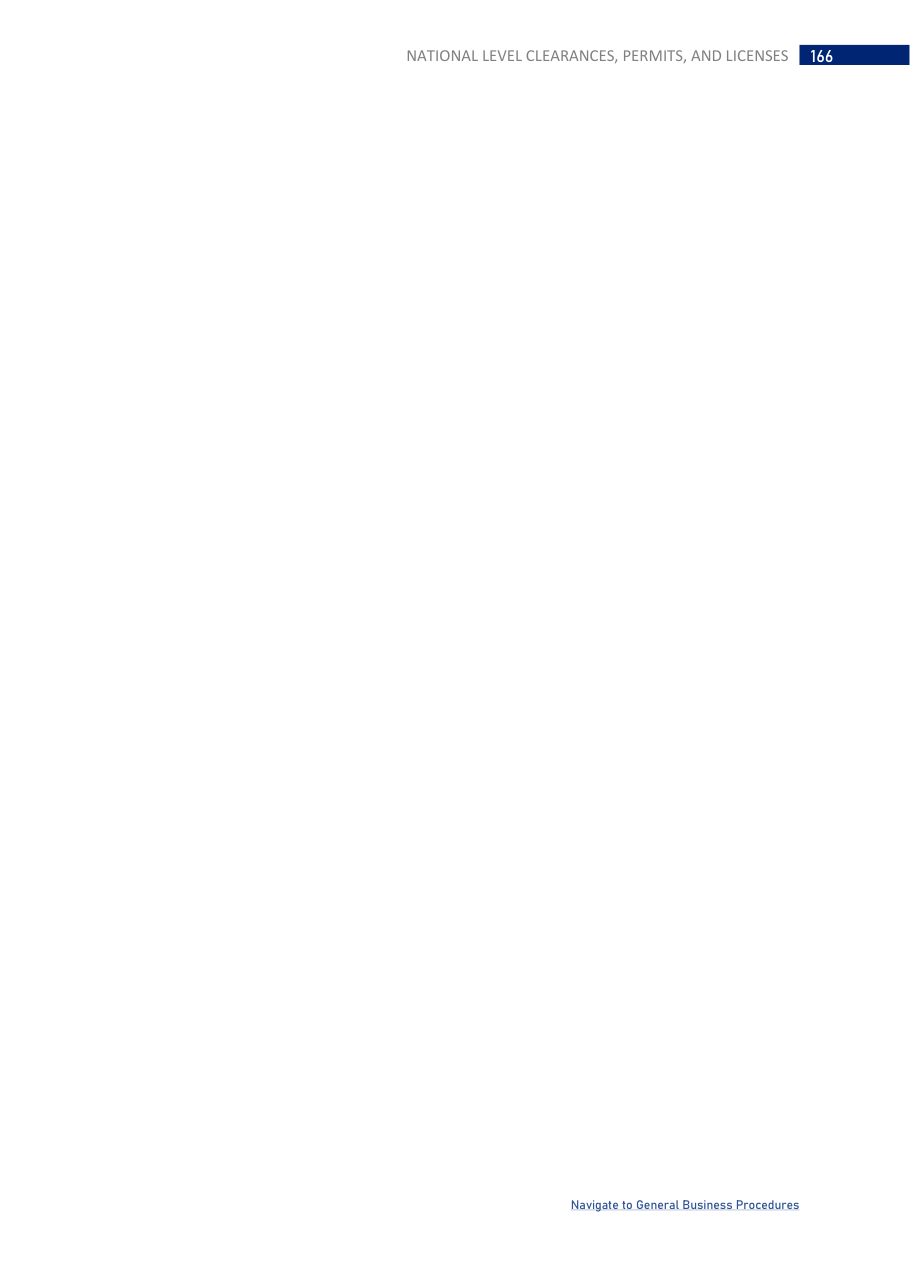

=== PDF Page 181 (910x1287) ===


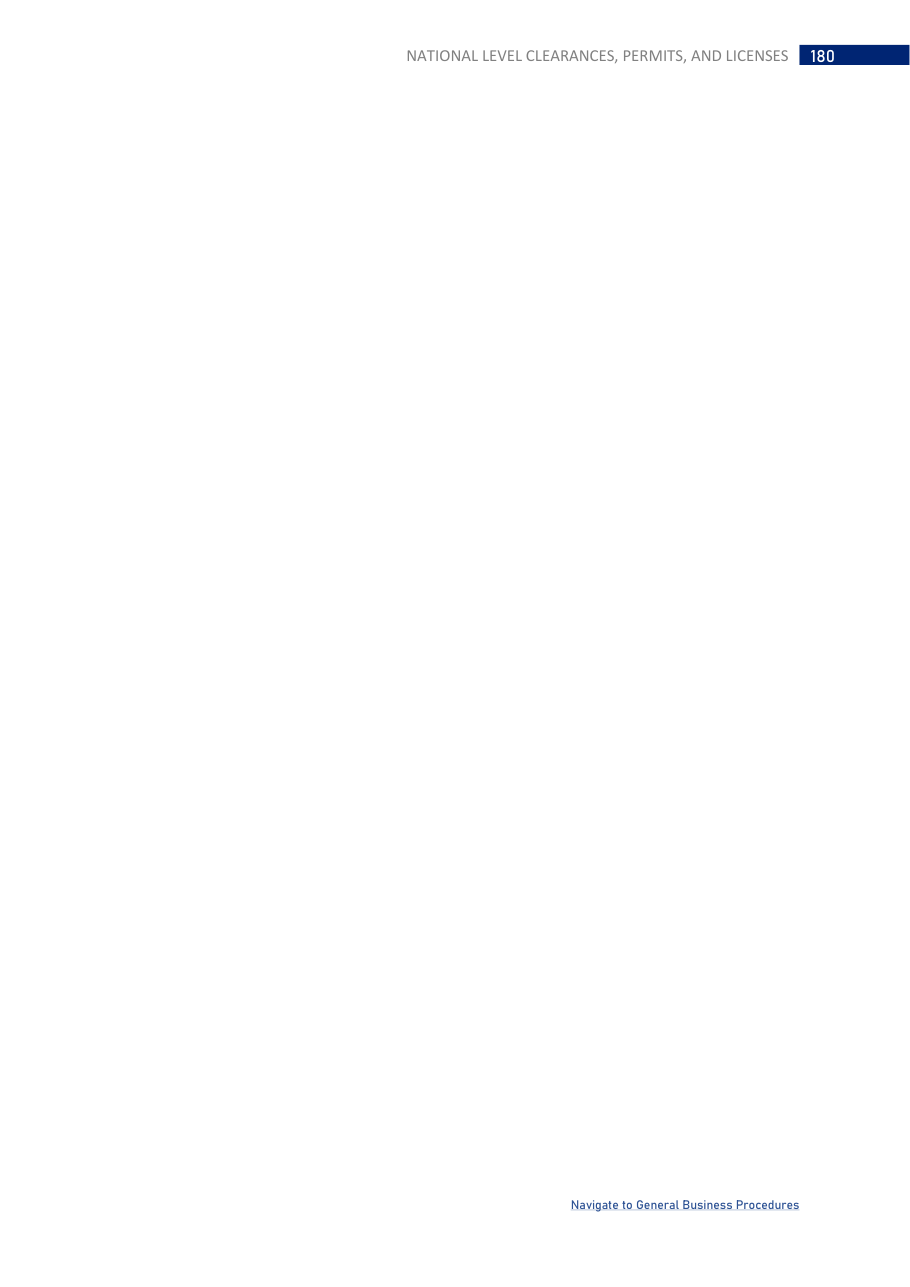

=== PDF Page 200 (910x1287) ===


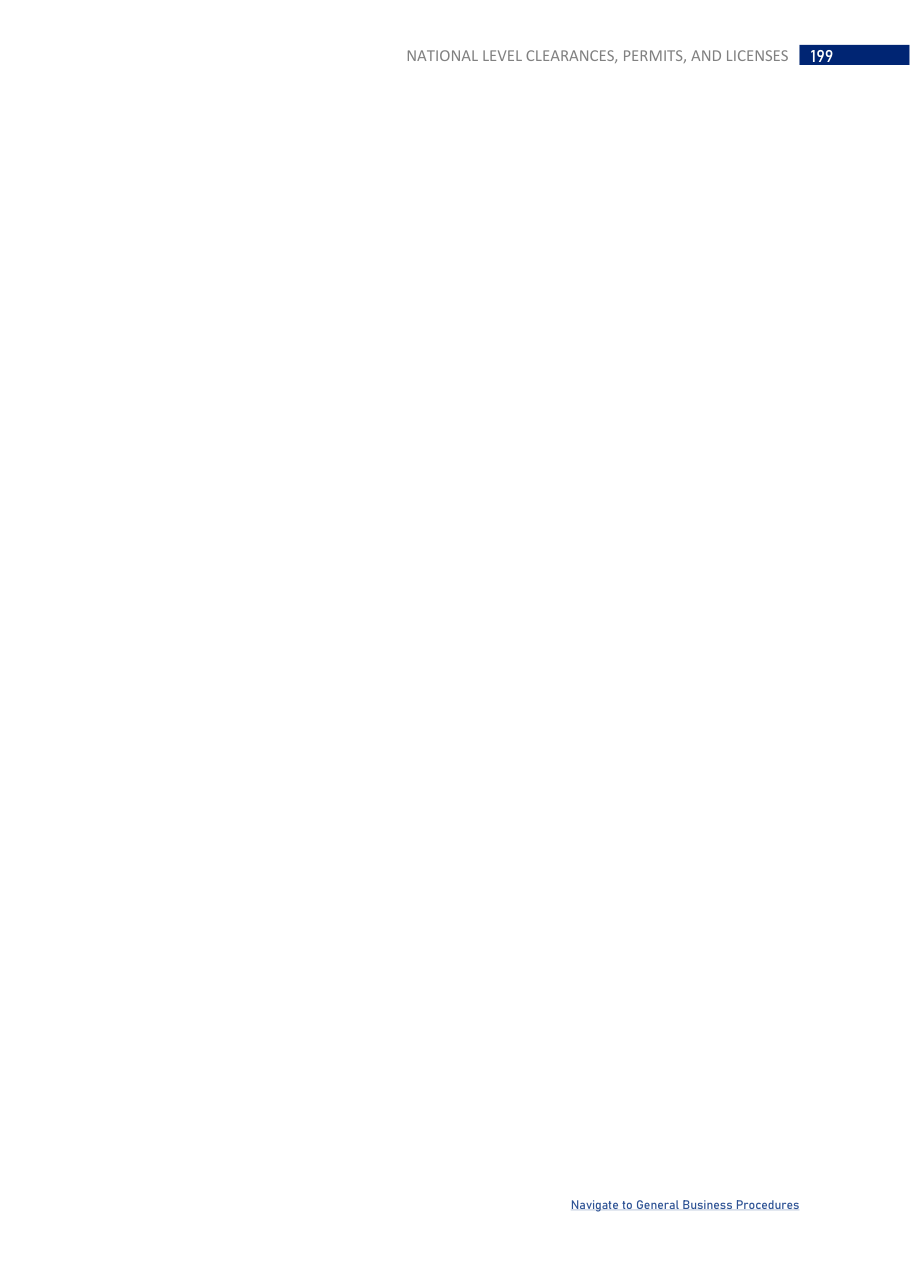

=== PDF Page 223 (910x1287) ===


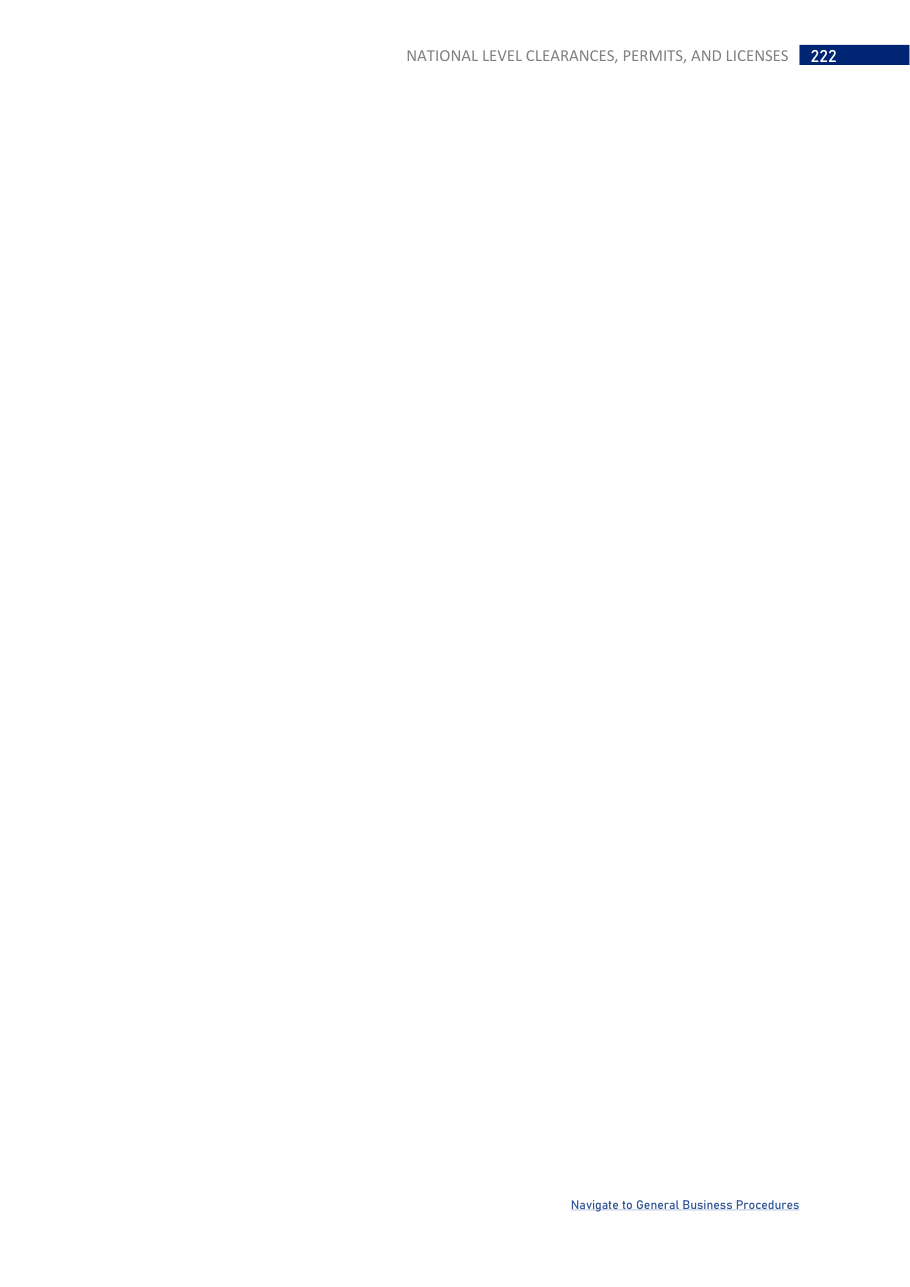

=== PDF Page 278 (910x1287) ===


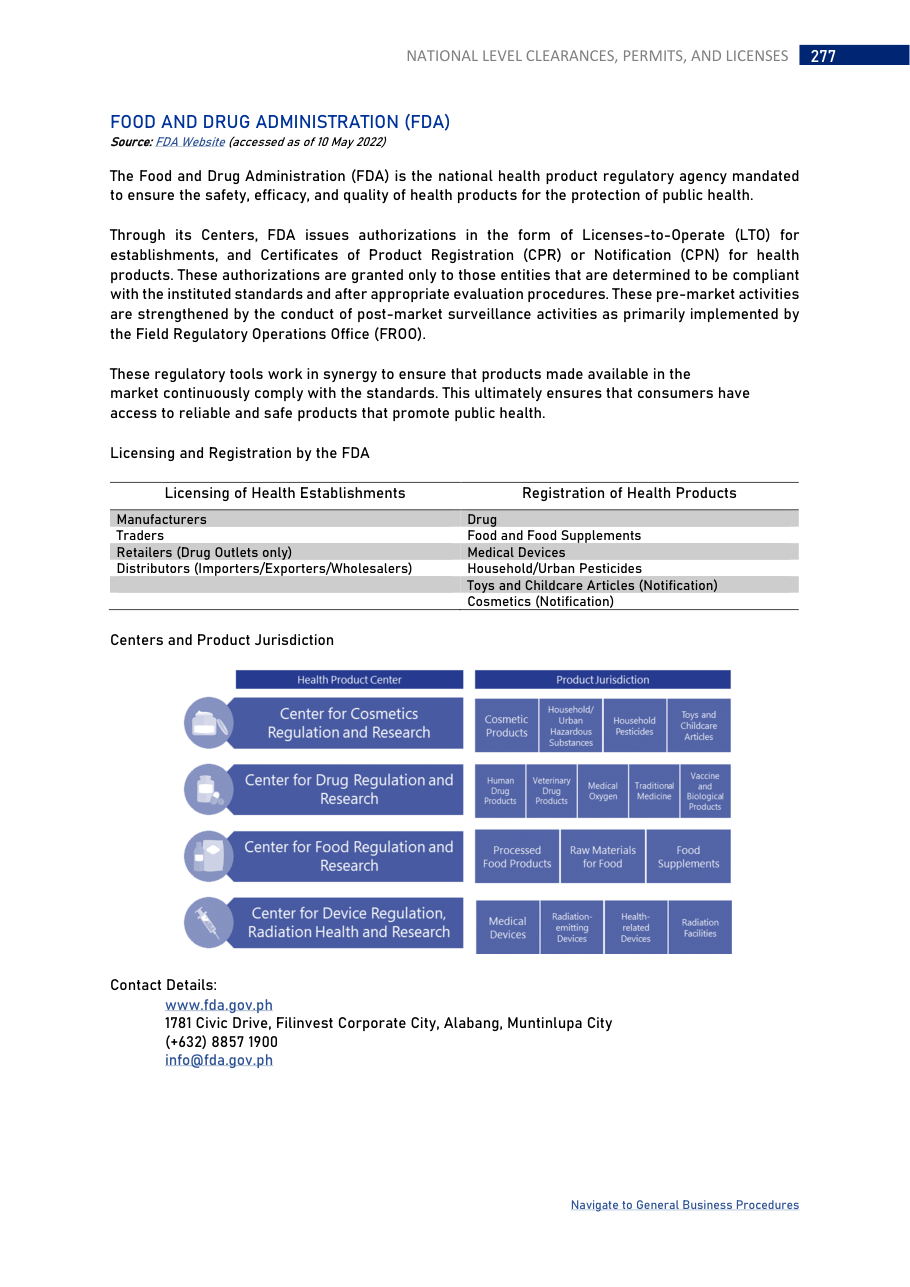

Page 278 page_type: content
Page 278 clean_text: 'FOOD AND DRUG ADMINISTRATION (FDA) \nSource: FDA Website (accessed as of 10 May 2022) \n \nThe Food and Drug Administration (FDA) is the national health product regulatory agency mandated \nto ensure the safety, efficacy, and quality of health products for the protection of public health. \n \nThrough its'


In [48]:
# Visual check: render the blank/image pages and page 278 to see what the extractor could not read
import fitz, io
from PIL import Image

doc = fitz.open(str(RAW_PDF))
try:
    for p_no in [167, 181, 200, 223, 278]:
        pix = doc[p_no - 1].get_pixmap(dpi=110)
        img = Image.open(io.BytesIO(pix.tobytes("png")))
        print(f"=== PDF Page {p_no} ({img.size[0]}x{img.size[1]}) ===")
        display(img)
finally:
    doc.close()

print("Page 278 page_type:", records[277]["page_type"])
print("Page 278 clean_text:", repr(records[277]["clean_text"][:300]))

## Cell 10: Before and after

In [49]:
import random
random.seed(42)
sample = sorted(random.sample(range(len(records)), 7) + [118, 299])   # plus the two table pages (index = page - 1)

# For each page, print raw_text[:600] and clean_text[:600] and check that no cleaning rule removed real content
for idx in sample:
    rec = records[idx]
    print(f"==================== PDF PAGE {rec['pdf_page']} ({rec['page_type']}) ====================")
    print("[RAW[:600]]")
    print(rec["raw_text"][:600])
    print("\n[CLEAN[:600]]")
    print(rec["clean_text"][:600])
    print()

==================== PDF PAGE 13 (content) ====================
[RAW[:600]]
 
Navigate to General Business Procedures  
 
12 VISA, EMPLOYMENT PERMITS, AND ALIEN REGISTRATION 
Alien Employment Permit (AEP) – New/Renewal 
Source: DOLE Citizen’s Charter 2022 Edition (Accessed as of 30 May 2022) 
Under Article 40 of the Labor Code of the Philippines, as amended, any alien seeking admission to the 
Philippines for employment purposes and any domestic or foreign employer who desires to engage 
an alien for employment in the Philippines shall obtain an employment permit from the Department of 
Labor and Employment.  
 
The Alien Employment Permit (AEP) is a permit issued to 

[CLEAN[:600]]
Alien Employment Permit (AEP) - New/Renewal 
Source: DOLE Citizen's Charter 2022 Edition (Accessed as of 30 May 2022) 
Under Article 40 of the Labor Code of the Philippines, as amended, any alien seeking admission to the 
Philippines for employment purposes and any domestic or foreign employer who desires t

## Cell 11: Save to Drive

In [50]:
import json, csv

# Save records to pages_clean.jsonl (one JSON object per line) and the cleaning log to cleaning_log.csv, then reload and check the count
jsonl_path = PROCESSED / "pages_clean.jsonl"
with jsonl_path.open("w", encoding="utf-8") as f:
    for rec in records:
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")

log_csv_path = LOGS / "cleaning_log.csv"
with log_csv_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["rule", "count"])
    for rule, cnt in cleaning_log.items():
        writer.writerow([rule, cnt])

# Reload and verify
with jsonl_path.open("r", encoding="utf-8") as f:
    reloaded = [json.loads(line) for line in f if line.strip()]

assert len(reloaded) == 502, f"Reloaded {len(reloaded)} records instead of 502"
print(f"Saved {len(reloaded)} records to {jsonl_path} and log to {log_csv_path}")

Saved 502 records to /content/drive/MyDrive/AI3-Project/data/processed/pages_clean.jsonl and log to /content/drive/MyDrive/AI3-Project/logs/cleaning_log.csv


## Cell 12: Numbers for Progress Check 1

In [51]:
# Numbers for Progress Check 1: pages, characters before/after cleaning, pages per page_type, quality issues with page numbers
before_chars = sum(len(r["raw_text"]) for r in records)
after_chars = sum(len(r["clean_text"]) for r in records)

print(f"Total pages: {len(records)}")
print(f"Total characters before cleaning: {before_chars:,}")
print(f"Total characters after cleaning:  {after_chars:,} (delta: {after_chars - before_chars:+,})")
print("\nPages per page_type:")
for ptype, cnt in sorted(Counter(r["page_type"] for r in records).items()):
    print(f"  {ptype}: {cnt}")

print("\nQuality issues found (with PDF page numbers as evidence):")
print("  - Empty/image-only pages (<50 chars):", [r["pdf_page"] for r in records if len(r["clean_text"]) < 50])
print("  - Pages containing 'END OF TRANSACTION':", [r["pdf_page"] for r in records if "END OF TRANSACTION" in r["clean_text"]][:15], "... total:", sum("END OF TRANSACTION" in r["clean_text"] for r in records))
print("  - Pages missing printed_page label:", [r["pdf_page"] for r in records if r["printed_page"] is None])

Total pages: 502
Total characters before cleaning: 968,686
Total characters after cleaning:  909,123 (delta: -59,563)

Pages per page_type:
  back_cover: 1
  blank_or_image: 8
  content: 467
  cover: 1
  directory: 6
  divider: 7
  front_matter: 1
  section_heading: 4
  toc: 7

Quality issues found (with PDF page numbers as evidence):
  - Empty/image-only pages (<50 chars): [3, 11, 12, 25, 32, 65, 66, 99, 111, 125, 151, 167, 176, 181, 184, 200, 223, 444, 458, 496]
  - Pages containing 'END OF TRANSACTION': [28, 31, 40, 42, 45, 48, 51, 53, 57, 60, 64, 70, 73, 93, 98] ... total: 137
  - Pages missing printed_page label: [1, 502]


## Week 1 findings and development questions


In [52]:
from IPython.display import Markdown, display

n_eot = sum("END OF TRANSACTION" in r["raw_text"] for r in records)
tiny = [(r["pdf_page"], r["page_type"]) for r in records if len(r["clean_text"]) < 50]
blank = [p for p, t in tiny if t == "blank_or_image"]
offset_pages = sum(1 for r in records if r["printed_page"] and r["printed_page"].isdigit()
                   and r["pdf_page"] - int(r["printed_page"]) == 1)

display(Markdown(f"""### Week 1 inspection findings
- **Header and footer on every page:** each content page starts with a running header (`<page number> <chapter title>`) and ends with a "Navigate to General Business Procedures" line. The footer appears on {cleaning_log['footer_lines']} pages and is removed by `remove_footer`; the header is parsed into `printed_page` and `section_title` by `parse_page_label` (page 1 and 502 have none).
- **Page numbering:** PDF page = printed page + 1 on {offset_pages} numeric pages, with no exceptions (asserted in Cell 9). Roman-numeral pages are front matter.
- **Page types:** {dict(Counter(r['page_type'] for r in records))}. Empty or image-only pages (under 50 characters): {blank} are blank or image pages; the other tiny pages are dividers and section headings.
- **Procedure markers:** {n_eot} pages contain "END OF TRANSACTION", which closes a step table and is useful for boundaries; "Agency Involved:" lines name the agency for the procedure that follows.
- **Line-end hyphens:** {cleaning_log['hyphen_newlines_joined']} `word-<newline>word` cases are joined by removing only the line break, which keeps real hyphenated words such as `non-immigrant` and `e-tablet`.
- **Extraction quirks:** pypdf splits words in places (`int ernational` on p. 2, `non -resident` on p. 13) and interleaves the columns of tables, which is why tables are read with pdfplumber in Week 2. Page 278 is an FDA infographic whose diagram text is not in the data.
- **Characters:** {cleaning_log['quote_dash_changes']} curly quotes and en dashes were mapped to ASCII; the peso sign, n with tilde and bullets are kept.
"""))


### Week 1 inspection findings
- **Header and footer on every page:** each content page starts with a running header (`<page number> <chapter title>`) and ends with a "Navigate to General Business Procedures" line. The footer appears on 500 pages and is removed by `remove_footer`; the header is parsed into `printed_page` and `section_title` by `parse_page_label` (page 1 and 502 have none).
- **Page numbering:** PDF page = printed page + 1 on 491 numeric pages, with no exceptions (asserted in Cell 9). Roman-numeral pages are front matter.
- **Page types:** {'cover': 1, 'front_matter': 1, 'divider': 7, 'toc': 7, 'section_heading': 4, 'content': 467, 'blank_or_image': 8, 'directory': 6, 'back_cover': 1}. Empty or image-only pages (under 50 characters): [32, 65, 125, 151, 167, 181, 200, 223] are blank or image pages; the other tiny pages are dividers and section headings.
- **Procedure markers:** 137 pages contain "END OF TRANSACTION", which closes a step table and is useful for boundaries; "Agency Involved:" lines name the agency for the procedure that follows.
- **Line-end hyphens:** 55 `word-<newline>word` cases are joined by removing only the line break, which keeps real hyphenated words such as `non-immigrant` and `e-tablet`.
- **Extraction quirks:** pypdf splits words in places (`int ernational` on p. 2, `non -resident` on p. 13) and interleaves the columns of tables, which is why tables are read with pdfplumber in Week 2. Page 278 is an FDA infographic whose diagram text is not in the data.
- **Characters:** 989 curly quotes and en dashes were mapped to ASCII; the peso sign, n with tilde and bullets are kept.


### Draft development questions (5)
These are written from the guidebook text and are used later to check retrieval. The `must_contain` text is checked against the page in the next cell, so each expected answer is traceable to a page.


In [53]:
DEV_QUESTIONS = [
    {"q": "What is the BOI registration fee for a micro project?",
     "expected": "PhP 3,000", "pdf_page": 465, "must_contain": "3,000"},
    {"q": "What is the minimum age of a principal applicant for the Special Retiree's Resident Visa (SRRV)?",
     "expected": "At least 35 years old", "pdf_page": 39, "must_contain": "at least 35 years old"},
    {"q": "Which BIR form is needed to apply online for a TIN for a local employee, and by when must the documents be submitted?",
     "expected": "BIR Form No. 1902 through eREG, before the 10th day of the following month", "pdf_page": 68, "must_contain": "BIR Form No. 1902"},
    {"q": "How long is the work covered by a Special Work Permit (SWP) - Commercial?",
     "expected": "Gainful employment of three to six months", "pdf_page": 20, "must_contain": "three to six months"},
    {"q": "Which office issues the Certificate of Registration of Job Contractors and Sub-contractors?",
     "expected": "DOLE Regional Offices (Articles 106 to 109 of the Labor Code)", "pdf_page": 454, "must_contain": "DOLE Regional Offices"},
]

_by_page = {r["pdf_page"]: " ".join(r["clean_text"].split()) for r in records}   # line wraps -> single spaces
for i, d in enumerate(DEV_QUESTIONS, start=1):
    ok = d["must_contain"].lower() in _by_page[d["pdf_page"]].lower()
    assert ok, f"Q{i}: '{d['must_contain']}' not found on PDF page {d['pdf_page']}"
    print(f"Q{i} (PDF p. {d['pdf_page']}): {d['q']}\n    expected: {d['expected']}")
print("All 5 expected answers found on their pages.")


Q1 (PDF p. 465): What is the BOI registration fee for a micro project?
    expected: PhP 3,000
Q2 (PDF p. 39): What is the minimum age of a principal applicant for the Special Retiree's Resident Visa (SRRV)?
    expected: At least 35 years old
Q3 (PDF p. 68): Which BIR form is needed to apply online for a TIN for a local employee, and by when must the documents be submitted?
    expected: BIR Form No. 1902 through eREG, before the 10th day of the following month
Q4 (PDF p. 20): How long is the work covered by a Special Work Permit (SWP) - Commercial?
    expected: Gainful employment of three to six months
Q5 (PDF p. 454): Which office issues the Certificate of Registration of Job Contractors and Sub-contractors?
    expected: DOLE Regional Offices (Articles 106 to 109 of the Labor Code)
All 5 expected answers found on their pages.


## Week 2: Structure and chunking
Parse the Table of Contents to map chapters, agencies, and procedures across pages, then build structure-aware chunks with breadcrumb context so steps and table rows stay intact for retrieval.

Cell W2-1 (Code) — Load pages

In [54]:
import json
from collections import Counter

# toc pages are kept in `records` for TOC parsing, but are NOT chunked (they only add retrieval noise)
W2_EXCLUDED_TYPES = {"cover", "back_cover", "divider", "toc"}

def load_pages(jsonl_path, excluded_types=W2_EXCLUDED_TYPES):
    loaded = []
    with open(jsonl_path, "r", encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            rec = json.loads(line)
            if rec.get("page_type") not in excluded_types:
                loaded.append(rec)
    return loaded

w2_pages = load_pages(PROCESSED / "pages_clean.jsonl")
print("Loaded page count:", len(w2_pages))
print("Counts per page_type:", dict(Counter(pg.get("page_type") for pg in w2_pages)))


Loaded page count: 486
Counts per page_type: {'front_matter': 1, 'section_heading': 4, 'content': 467, 'blank_or_image': 8, 'directory': 6}


Cell W2-2 (Code) — Parse TOC

In [55]:
import re

ROMAN_RE = re.compile(
    r"^(?:m{0,4}(?:cm|cd|d?c{0,3})(?:xc|xl|l?x{0,3})(?:ix|iv|v?i{0,3}))$",
    re.IGNORECASE,
)

CHAPTER_TITLES = {
    "GENERAL BUSINESS PROCEDURE",
    "VISA, EMPLOYMENT PERMITS, AND ALIEN REGISTRATION",
    "PERSONAL TAX IDENTIFICATION NUMBER (TIN)",
    "REGISTRATION OF INWARD INVESTMENTS",
    "NATIONAL LEVEL CLEARANCES, PERMITS, AND LICENSES",
    "PHILIPPINE LABOR CODE COMPLIANCE",
    "INCENTIVES AVAILMENT",
    "DIRECTORY OF CONTACTS",
}

AGENCY_RE = re.compile(
    r"\b(BUREAU|DEPARTMENT|COMMISSION|AUTHORITY|BOARD|OFFICE|AGENCY|ADMINISTRATION|CENTER|SERVICE|DOLE|BOI|SEC|BIR|FDA|FDAC)\b",
    re.IGNORECASE,
)
ACTION_PREFIX_RE = re.compile(
    r"^(Application|Issuance|Conversion|Registration|Filing|Request|Renewal|Endorsement|Extension)\b",
    re.IGNORECASE,
)

def _is_roman(tok: str) -> bool:
    return bool(tok and ROMAN_RE.match(tok.strip()))

AGENCY_RE = re.compile(
    r"\b(BUREAU|DEPARTMENT|COMMISSION|AUTHORITY|BOARD|OFFICE|AGENCY|ADMINISTRATION|CENTER|SERVICE|DOLE|BOI|SEC|BIR|FDA|FDAC)\b",
    re.IGNORECASE,
)
# A title that STARTS with an action noun is a procedure, even if it mentions an agency
# (e.g. "Certificate of Endorsement to the Energy Regulatory Commission").
ACTION_PREFIX_RE = re.compile(
    r"^(Application|Issuance|Conversion|Registration|Filing|Request|Renewal|Endorsement|Extension|"
    r"Certificate|Certification|Visa|Permit|Clearance|Accreditation|License|Licence|Payment|Submission|"
    r"Approval|Verification|Amendment|Cancellation|Change|Inspection|Notarization|Release|Securing|"
    r"Obtaining|Processing)\b",
    re.IGNORECASE,
)
# Step labels such as "9a Visa Issuance at ..." are always procedures.
STEP_LABEL_RE = re.compile(r"^\d+[a-z]?[.)]?\s+", re.IGNORECASE)

# Manual fixes after you eyeball the printout below, e.g. {"Pag-IBIG Fund": "agency"}
TOC_LEVEL_OVERRIDES = {
    # sections inside the BOARD OF INVESTMENTS chapter, not separate agencies
    "BOI Registration": "procedure",
    "Qualifications for BOI Registration": "procedure",
    "BOI Endorsements and Other Issuances": "procedure",
}

def classify_toc_level(title: str) -> str:
    t = title.strip()
    overrides = {k.lower(): v for k, v in TOC_LEVEL_OVERRIDES.items()}
    if t.lower() in overrides:
        return overrides[t.lower()]
    if t.upper() in CHAPTER_TITLES:
        return "chapter"
    if STEP_LABEL_RE.match(t) or ACTION_PREFIX_RE.match(t):
        return "procedure"
    if (AGENCY_RE.search(t)
            and len(t.split()) <= 12
            and not re.search(r"\b(at|to the)\b", t, re.IGNORECASE)):
        return "agency"
    return "procedure"

def parse_toc_entries(records, toc_pdf_pages=range(4, 11)):
    toc_map = {r["pdf_page"]: r for r in records if r.get("pdf_page") in toc_pdf_pages}
    entries = []
    pending_title_parts = []
    # A printed page is 1-3 digits. Allowing more let "...Section 16 of R.A. 11534" be read as
    # page 11534, which then poisoned every later TOC entry (see the clamp below).
    page_tail_re = re.compile(r"^(.*?)\s+([0-9]{1,3}|[ivxlcdmIVXLCDM]+)$")

    for p_no in toc_pdf_pages:
        pg = toc_map.get(p_no)
        if not pg:
            continue
        lines = [ln.strip() for ln in pg.get("clean_text", "").splitlines() if ln.strip()]
        for ln in lines:
            if ln.upper() in {"TABLE OF CONTENTS", "INTRODUCTION", "DISCLAIMER", "GENERAL BUSINESS PROCEDURE"} and not page_tail_re.match(ln):
                continue
            candidate = " ".join(pending_title_parts + [ln]).strip()
            m = page_tail_re.match(candidate)
            if m:
                raw_title = re.sub(r"\s+", " ", m.group(1)).strip(" .·-")
                page_tok = m.group(2).strip()
                if raw_title:
                    is_rom = _is_roman(page_tok)
                    printed_page = page_tok.lower() if is_rom else page_tok
                    pdf_page = None if is_rom else int(page_tok) + 1
                    entries.append({
                        "title": raw_title,
                        "printed_page": printed_page,
                        "pdf_page": pdf_page,
                        "is_roman": is_rom,
                        "level": classify_toc_level(raw_title),
                    })
                pending_title_parts = []
            else:
                if len(ln) <= 90:
                    pending_title_parts.append(ln)
                else:
                    pending_title_parts = [ln]

    last_pdf_p = 0
    for e in entries:
        if e["pdf_page"] is not None:
            if e["pdf_page"] < last_pdf_p:
                e["pdf_page"] = last_pdf_p
            last_pdf_p = e["pdf_page"]

    return entries

# Fallback if your Week 1 variable had another name
_source_pages = (
    records if "records" in globals()
    else clean_pages if "clean_pages" in globals()
    else []
)
# use the pages Week 1 tagged as 'toc' instead of a hard-coded page range
_toc_pages = [r["pdf_page"] for r in _source_pages if r.get("page_type") == "toc"]
toc_entries = parse_toc_entries(_source_pages, toc_pdf_pages=_toc_pages)
print("TOC pages used:", _toc_pages)
print(f"Parsed {len(toc_entries)} TOC entries")

# Sanity checks: every page must be inside the PDF, and pages must never go backwards.
_max_pdf_page = max(r["pdf_page"] for r in _source_pages)
_bad_range = [e for e in toc_entries if e["pdf_page"] is not None and e["pdf_page"] > _max_pdf_page]
assert not _bad_range, f"TOC entries beyond the last PDF page: {[(e['title'][:40], e['printed_page']) for e in _bad_range]}"
_prev, _backwards = 0, []
for e in toc_entries:
    if e["is_roman"]:
        continue
    n = int(e["printed_page"])
    if n < _prev:
        _backwards.append((e["title"][:50], n, _prev))
    _prev = max(_prev, n)
print("TOC entries whose printed page goes backwards (should be 0):", len(_backwards), _backwards[:5])

# Eyeball ALL entries by level. Fix mistakes with TOC_LEVEL_OVERRIDES above, then rerun this cell.
for lvl in ("chapter", "agency", "procedure"):
    items = [e for e in toc_entries if e["level"] == lvl]
    print(f"\n===== {lvl.upper()} ({len(items)}) =====")
    for e in items:
        print(f"  p{str(e['printed_page']):>5} | {e['title']}")


TOC pages used: [4, 5, 6, 7, 8, 9, 10]
Parsed 221 TOC entries
TOC entries whose printed page goes backwards (should be 0): 0 []

===== CHAPTER (8) =====
  p   ii | GENERAL BUSINESS PROCEDURE
  p   10 | VISA, EMPLOYMENT PERMITS, AND ALIEN REGISTRATION
  p   65 | PERSONAL TAX IDENTIFICATION NUMBER (TIN)
  p   98 | REGISTRATION OF INWARD INVESTMENTS
  p  110 | NATIONAL LEVEL CLEARANCES, PERMITS, AND LICENSES
  p  443 | PHILIPPINE LABOR CODE COMPLIANCE
  p  457 | INCENTIVES AVAILMENT
  p  495 | DIRECTORY OF CONTACTS

===== AGENCY (26) =====
  p   74 | SECURITIES AND EXCHANGE COMMISSION (SEC)
  p   83 | DEPARTMENT OF TRADE AND INDUSTRY (DTI)
  p   86 | COOPERATIVE DEVELOPMENT AUTHORITY (CDA)
  p  111 | INTELLECTUAL PROPERTY OFFICE (IPO)
  p  132 | DEPARTMENT OF ENVIRONMENT AND NATURAL RESOURCES - ENVIRONMENTAL MANAGEMENT BUREAU (DENR-EMB)
  p  140 | DEPARTMENT OF AGRARIAN REFORM (DAR)
  p  151 | DEPARTMENT OF ENERGY (DOE)
  p  152 | Energy Resources Development Bureau
  p  183 | Oil Industr

Cell W2-3 (Code) — Assign structure

In [56]:
from collections import defaultdict, Counter

AGENCY_OVERRIDE_RE = re.compile(
    r"(?:Agency\s+Involved|Implementing\s+Agency|Lead\s+Agency)\s*:\s*(.+)",
    re.IGNORECASE,
)

def _norm_title(s: str) -> str:
    """Normalise a heading so a page's first line can be compared with a TOC title."""
    s = re.sub(r"^\s*\d+[a-z]?[.)]?\s+", "", s, flags=re.IGNORECASE)   # drop '9a ' step label
    s = s.lower().replace("&", "and")
    s = re.sub(r"[^a-z0-9 ]+", " ", s)
    return re.sub(r"\s+", " ", s).strip()

def _build_title_index(numeric_entries):
    idx = defaultdict(list)
    for e in numeric_entries:
        if e["level"] in ("agency", "procedure"):
            idx[_norm_title(e["title"])].append(e)
    return idx

def match_heading(clean_text, title_index, pdf_page, max_lines=3, max_page_gap=2):
    """Match the first 1-3 lines of a page against TOC titles (must be within max_page_gap pages)."""
    lines = [ln.strip() for ln in clean_text.splitlines() if ln.strip()][:max_lines]
    for n in range(1, len(lines) + 1):
        key = _norm_title(" ".join(lines[:n]))
        for e in title_index.get(key, []):
            if abs(e["pdf_page"] - pdf_page) <= max_page_gap:
                return e
    return None

def assign_page_structure(content_records, toc_entries):
    numeric_entries = [
        e for e in toc_entries
        if not e.get("is_roman") and e.get("pdf_page") is not None
    ]
    numeric_entries.sort(key=lambda x: x["pdf_page"])
    title_index = _build_title_index(numeric_entries)

    current_chapter = "GENERAL BUSINESS PROCEDURE"
    current_agency = "BOI"
    current_procedure = "General Procedure"
    entry_idx = 0
    n_entries = len(numeric_entries)

    structured = []
    run_id, prev_key = 0, None
    for rec in sorted(content_records, key=lambda r: r["pdf_page"]):
        p = rec["pdf_page"]
        source = "carried_over"

        # 1) walk the TOC: every entry whose page is <= this page applies
        while entry_idx < n_entries and numeric_entries[entry_idx]["pdf_page"] <= p:
            ent = numeric_entries[entry_idx]
            lvl = ent["level"]
            if lvl == "chapter":
                current_chapter = ent["title"]
                current_agency = "BOI"
                current_procedure = "General Procedure"
            elif lvl == "agency":
                current_agency = ent["title"]
                current_procedure = "General Procedure"
            else:
                current_procedure = ent["title"]
            source = "toc_page"
            entry_idx += 1

        # 2) confirm / correct with the page's own first line (NOT the running header)
        hit = match_heading(rec.get("clean_text", ""), title_index, p)
        if hit is not None:
            if hit["level"] == "agency":
                current_agency = hit["title"]
            else:
                current_procedure = hit["title"]
            source = "first_line"

        # 3) a "run" = consecutive pages with the same (chapter, TOC agency, procedure)
        key = (current_chapter, current_agency, current_procedure)
        if key != prev_key:
            run_id += 1
            prev_key = key

        m_agency = AGENCY_OVERRIDE_RE.search(rec.get("clean_text", ""))
        out = dict(rec)
        out["chapter"] = current_chapter or "General Business Procedure"
        out["toc_agency"] = current_agency or "BOI"
        out["procedure"] = current_procedure or "General Procedure"
        out["structure_source"] = source
        out["_run"] = run_id
        out["_page_agency"] = m_agency.group(1).strip(" .;\t") if m_agency else None
        structured.append(out)

    # 4) the "Agency Involved:" line is printed only on one page of a procedure, but it
    #    describes the WHOLE procedure: the first such line in a run wins for every page of that run.
    run_agency = {}
    for r in structured:
        if r["_page_agency"] and r["_run"] not in run_agency:
            run_agency[r["_run"]] = r["_page_agency"]
    for r in structured:
        ov = run_agency.get(r["_run"])
        r["agency"] = ov or r["toc_agency"]
        r["agency_source"] = "page_override" if ov else "toc"
        del r["_page_agency"]
    return structured

content_records = [
    r for r in _source_pages
    if r.get("page_type", "content") not in W2_EXCLUDED_TYPES      # toc pages are excluded here
]
structured_content_pages = assign_page_structure(content_records, toc_entries)
print(f"Structured {len(structured_content_pages)} content pages")

# ---- Check: the guidebook has many procedures, so expect about 100 or more distinct values ----
n_proc = len({r["procedure"] for r in structured_content_pages})
print("Distinct procedures:", n_proc, "(expected about 100 or more)" if n_proc >= 100 else "  <-- LOW, check classify_toc_level / TOC parsing")
print("Pages by structure_source:", dict(Counter(r["structure_source"] for r in structured_content_pages)))

# ---- Check: after the fix each (chapter, procedure) must have ONE agency ----
# "General Procedure" is the per-agency overview bucket, so it is allowed to differ by agency.
_ag = defaultdict(set)
for r in structured_content_pages:
    if r["procedure"] != "General Procedure":
        _ag[(r["chapter"], r["procedure"])].add(r["agency"])
_multi = {k: v for k, v in _ag.items() if len(v) > 1}
print("Procedures with more than one agency (should be 0):", len(_multi))
for k, v in list(_multi.items())[:10]:
    print("  ", k[1][:60], "->", sorted(v))
print("Agency values that came from 'Agency Involved:' overrides:", sum(r["agency_source"] == "page_override" for r in structured_content_pages), "pages")
print("Top 5 procedures by page count:", Counter(r["procedure"] for r in structured_content_pages).most_common(5))


Structured 486 content pages
Distinct procedures: 171 (expected about 100 or more)
Pages by structure_source: {'carried_over': 290, 'first_line': 191, 'toc_page': 5}
Procedures with more than one agency (should be 0): 0
Agency values that came from 'Agency Involved:' overrides: 55 pages
Top 5 procedures by page count: [('General Procedure', 26), ('Certificate of Product Registration (CPR) of Biologicals and Vaccines Except Cancer Drugs (New Chemical Entities/Monitored Release and Initial)', 11), ('Certificate of Product Registration', 11), ('Certificate of Product Registration (CPR) of Pharmaceutical Products (Initial - Reproductive Health Products)', 9), ("Conversion to Treaty Trader's/Treaty Investor's Visa - Section 9(D)", 8)]


Cell W2-3b (Code) — Chapter from the running header

In [57]:
# The chapter of a chunk must be the title printed in the page's running header (`section_title`, parsed in Week 1).
# Check PDF pages 74-97 first, then correct `chapter` for every page.
PAGES_74_97 = set(range(74, 98))
section_title_by_page = {r["pdf_page"]: r["section_title"] for r in records}

for p in structured_content_pages:
    p.setdefault("toc_chapter", p["chapter"])        # keep the original TOC-walk value (set once, so re-running is safe)

in_range = [p for p in structured_content_pages if p["pdf_page"] in PAGES_74_97]
chapters_before = Counter(p["toc_chapter"] for p in in_range)
titles_in_range = Counter(section_title_by_page[p["pdf_page"]] for p in in_range)
print(f"Pages 74-97: {len(chapters_before)} distinct chapter value(s) from the TOC walk: {dict(chapters_before)}")
print(f"Pages 74-97: {len(titles_in_range)} distinct section_title value(s) in records:   {dict(titles_in_range)}")

# Apply the fix: chapter = section_title (changes are counted against the original TOC value)
changed = []
for p in structured_content_pages:
    title = section_title_by_page.get(p["pdf_page"])
    if title and p["toc_chapter"] != title:
        changed.append((p["pdf_page"], p["toc_chapter"], title))
    if title:
        p["chapter"] = title
missing_title = [p["pdf_page"] for p in structured_content_pages if not section_title_by_page.get(p["pdf_page"])]

CHAPTER_FIX = {
    "distinct_before": len(chapters_before),
    "distinct_after": len({p["chapter"] for p in in_range}),
    "titles_in_range": "; ".join(sorted(titles_in_range)),
    "changed_total": len(changed),
    "changed_in_range": sum(1 for c in changed if c[0] in PAGES_74_97),
}
print(f"\nPages whose chapter was changed: {len(changed)} (in pages 74-97: {CHAPTER_FIX['changed_in_range']})")
print("Pages without a section_title (chapter kept from the TOC):", missing_title)
print("Changes outside pages 74-97 (old TOC value -> section_title), one line per pair:")
for pair, n in Counter((old, new) for pg_, old, new in changed if pg_ not in PAGES_74_97).most_common():
    print(f"  {n:>3} pages: {pair[0]!r} -> {pair[1]!r}")

assert all(p["chapter"] == section_title_by_page[p["pdf_page"]]
           for p in structured_content_pages if section_title_by_page.get(p["pdf_page"])), "chapter still differs from section_title"
print("\nNext: re-run W2-4 onward (blocks, chunks, experiment, validation, save) so chunks.jsonl is rebuilt.")

Pages 74-97: 1 distinct chapter value(s) from the TOC walk: {'PERSONAL TAX IDENTIFICATION NUMBER (TIN)': 24}
Pages 74-97: 2 distinct section_title value(s) in records:   {'BUSINESS ENTERPRISE REGISTRATION AND LICENSING': 16, 'BUSINESS TAXATION': 8}

Pages whose chapter was changed: 27 (in pages 74-97: 24)
Pages without a section_title (chapter kept from the TOC): []
Changes outside pages 74-97 (old TOC value -> section_title), one line per pair:
    1 pages: 'GENERAL BUSINESS PROCEDURE' -> 'INTRODUCTION'
    1 pages: 'PERSONAL TAX IDENTIFICATION NUMBER (TIN)' -> 'BUSINESS TAXATION'
    1 pages: 'INCENTIVES AVAILMENT' -> 'ACKNOWLEDGEMENT'

Next: re-run W2-4 onward (blocks, chunks, experiment, validation, save) so chunks.jsonl is rebuilt.


Cell W2-4 (Code) — Block splitter

In [58]:
from pathlib import Path
import fitz
import pdfplumber

assert Path(RAW_PDF).exists(), f"Missing RAW_PDF: {RAW_PDF}"
_doc_check = fitz.open(str(RAW_PDF))
assert len(_doc_check) == len(pages), f"PDF has {len(_doc_check)} pages but Week 1 loaded {len(pages)}"
_doc_check.close()

MIN_TABLE_ROWS, MIN_TABLE_COLS = 2, 2
# Every content page has its running header at y~32 and the "Navigate to..." footer at y~786
# (checked on all 486 pages); body text lives between y~74 and y~771. Crop to that band.
HEADER_BOTTOM, FOOTER_TOP = 60.0, 780.0     # ignore 1-row / 1-column "tables" (usually layout lines)

def _collapse_cell(val) -> str:
    if val is None:
        return ""
    return re.sub(r"\s+", " ", str(val)).strip()

def _clean_fragment(text, rec=None, first=False):
    """Apply the SAME Week 1 cleaning rules to a piece of text pulled from pdfplumber."""
    t, _ = remove_footer(text)
    if first:
        t, _, _ = parse_page_label(t)
    t, _ = fix_hyphenation(t)
    t, _ = normalize_bullets(t)
    t, _ = normalize_quotes_dashes(t)
    t, _ = collapse_whitespace(t)
    # safety net: drop any line that is exactly the running header, in EITHER order.
    # pdfplumber gives "TITLE 112" while pypdf gave "112 TITLE".
    if rec and rec.get("printed_page") and rec.get("section_title"):
        num, title = re.escape(str(rec["printed_page"])), re.escape(rec["section_title"])
        hdr = re.compile(rf"^[ \t]*(?:{num}[ \t]+{title}|{title}[ \t]+{num})[ \t]*$", re.IGNORECASE | re.MULTILINE)
        t = hdr.sub("", t)
        t = re.sub(r"\n{3,}", "\n\n", t).strip()
    return t

_BULLET_RE = re.compile(r"^(?:•|-|\d+[.)]|[a-zA-Z][.)])\s+")

def _text_to_blocks(text, p_no, printed):
    """Split plain text into paragraph / list_item blocks (no table logic here)."""
    blocks, para_buf = [], []

    def flush():
        nonlocal para_buf
        if para_buf:
            blocks.append({"type": "paragraph", "text": " ".join(para_buf).strip(),
                           "pdf_page": p_no, "printed_page": printed})
            para_buf = []

    in_list_item = False          # True while the previous line belonged to a list item
    for line in text.splitlines():
        s = line.strip()
        if not s:
            flush()
            in_list_item = False
            continue
        if _BULLET_RE.match(s):
            flush()
            blocks.append({"type": "list_item", "text": s, "pdf_page": p_no, "printed_page": printed})
            in_list_item = True
        elif in_list_item and s[:1].islower():
            # wrapped second line of a list item ("...with TIN of Filipino" / "partners including..."):
            # keep it with its own label instead of starting a lowercase "paragraph"
            blocks[-1]["text"] += " " + s
        else:
            in_list_item = False
            para_buf.append(s)
    flush()
    return blocks

def _page_tables(plumber_page):
    """Real tables only: (bbox, rows). Sorted top to bottom."""
    found = []
    for t in plumber_page.find_tables():
        rows = t.extract()
        n_cols = max((len(r) for r in rows), default=0)
        if len(rows) >= MIN_TABLE_ROWS and n_cols >= MIN_TABLE_COLS:
            found.append((t.bbox, rows))
    found.sort(key=lambda x: x[0][1])
    return found

def extract_page_blocks(plumber_page, page_record):
    """Blocks in READING ORDER. Table text is taken from the table's bounding box only,
    and all other text from the regions ABOVE / BETWEEN / BELOW the tables, so nothing is
    matched by substring and nothing is duplicated or dropped."""
    p_no = page_record["pdf_page"]
    printed = page_record.get("printed_page")
    tables = _page_tables(plumber_page)

    # No tables: keep the Week 1 clean_text exactly as it is.
    if not tables:
        return _text_to_blocks(page_record.get("clean_text", ""), p_no, printed)

    W, H = float(plumber_page.width), float(plumber_page.height)
    blocks, cursor, first_region = [], HEADER_BOTTOM, True

    def add_text_region(y0, y1):
        nonlocal first_region
        y0, y1 = max(HEADER_BOTTOM, y0), min(FOOTER_TOP, y1)
        if y1 - y0 < 1:
            return
        txt = plumber_page.within_bbox((0, y0, W, y1)).extract_text() or ""
        txt = _clean_fragment(txt, page_record, first=first_region)
        if txt.strip():
            first_region = False
            blocks.extend(_text_to_blocks(txt, p_no, printed))

    for t_idx, (bbox, rows) in enumerate(tables):
        x0, top, x1, bottom = bbox
        if top > cursor:
            add_text_region(cursor, top)           # text ABOVE this table
        table_id = f"p{p_no}_t{t_idx}"
        for r_idx, row in enumerate(rows):
            cells = [_collapse_cell(c) for c in row if _collapse_cell(c)]
            if cells:
                blocks.append({"type": "table_row", "text": " | ".join(cells),
                               "pdf_page": p_no, "printed_page": printed,
                               "table_id": table_id, "row_idx": r_idx})
        first_region = False
        cursor = max(cursor, bottom)
    add_text_region(cursor, FOOTER_TOP)            # text BELOW the last table
    return blocks

with pdfplumber.open(str(RAW_PDF)) as _pdf:
    blocks_by_page = {
        pg["pdf_page"]: extract_page_blocks(_pdf.pages[pg["pdf_page"] - 1], pg)
        for pg in structured_content_pages
    }

total_blocks = sum(len(v) for v in blocks_by_page.values())
print(f"Extracted {total_blocks} blocks across {len(blocks_by_page)} pages")
print("Block types:", dict(Counter(b["type"] for v in blocks_by_page.values() for b in v)))


Extracted 7634 blocks across 486 pages
Block types: {'paragraph': 1569, 'list_item': 3393, 'table_row': 2672}


In [59]:
# Per-page word coverage: words in blocks vs words in the page's clean_text.
# (Table separators " | " are not counted as words.) Expect ratios close to 1.0.
def _words(s):
    return len(s.replace("|", " ").split())

coverage = []
for pg in structured_content_pages:
    n_clean = _words(pg["clean_text"])
    n_blocks = sum(_words(b["text"]) for b in blocks_by_page[pg["pdf_page"]])
    ratio = n_blocks / n_clean if n_clean else None
    coverage.append((pg["pdf_page"], n_clean, n_blocks, ratio))

tot_clean = sum(c[1] for c in coverage)
tot_blocks = sum(c[2] for c in coverage)
print(f"Overall: blocks have {tot_blocks:,} words vs {tot_clean:,} in clean_text "
      f"({(tot_blocks / tot_clean - 1) * 100:+.1f}%)")

bad = [c for c in coverage if c[3] is not None and abs(c[3] - 1) > 0.10 and abs(c[2] - c[1]) >= 15]
print(f"Pages off by more than 10% and 15 words: {len(bad)}")
for p, nc, nb, r in sorted(bad, key=lambda c: abs(c[2] - c[1]), reverse=True)[:15]:
    print(f"  page {p}: clean_text={nc}, blocks={nb}, ratio={r:.2f}")

for p in (78, 119):                      # spot-check two pages: word coverage and reading order
    row = next((c for c in coverage if c[0] == p), None)
    print("page", p, "->", row)

def show_blocks(page_no, n=12):
    """Eyeball the reading order of one page."""
    for b in blocks_by_page[page_no][:n]:
        print(f"  [{b['type']:<9}] {b['text'][:110]}")
for _p in (119, 78):
    if _p in blocks_by_page:
        print(f"--- blocks on page {_p} (reading order) ---")
        show_blocks(_p)

# Running-header leak check: a page header looks like "NATIONAL LEVEL CLEARANCES, PERMITS, AND LICENSES 112"
# (title first, number after, in pdfplumber) or "112 TITLE" (pypdf). Neither order may appear in block text.
_titles = {r["section_title"] for r in records if r.get("section_title")}
_alt = "|".join(re.escape(t) for t in _titles)
HEADER_LEAK_RE = re.compile(rf"\b\d+\s+(?:{_alt})\b|\b(?:{_alt})\s+\d+\b")
_leaky_blocks = [(p, b["text"][:80]) for p, bl in blocks_by_page.items() for b in bl if HEADER_LEAK_RE.search(b["text"])]
print("Blocks containing a running header (should be 0):", len(_leaky_blocks), _leaky_blocks[:3])


Overall: blocks have 129,556 words vs 129,681 in clean_text (-0.1%)
Pages off by more than 10% and 15 words: 0
page 78 -> (78, 301, 300, 0.9966777408637874)
page 119 -> (119, 322, 323, 1.0031055900621118)
--- blocks on page 119 (reading order) ---
  [table_row] filing, the applicant receives FER but without Notice of 1st Publication] | incomplete/with deficiencies upon 
  [table_row] 2 | Filing of response to 1st FER for applications with deficiencies upon filing (filed within 2 months from t
  [table_row] 4 | Request for Extension of time to file a response (filed on or before the due date of the applicant’s respo
  [table_row] 5 | Request for Revival of Withdrawn Application - with cost - without cost (filed within 4 months from the ma
  [table_row] 6 | Filing of a Voluntary Divisional Application | FER for divisional application | Fee for divisional applica
--- blocks on page 78 (reading order) ---
  [paragraph] Through ESPARC (Electronic Simplified Processing of Application for Reg

Cell W2-5 (Code) — Chunk builder

In [60]:
from collections import defaultdict

# Prefer to cut an oversized block after a sentence end OR after ";" (list items such as "...; 7. Application ...")
SENTENCE_SPLIT_RE = re.compile(r"(?<=[.!?;])\s+")

def _split_words(text, max_len):
    out, buf = [], ""
    for w in text.split():
        cand = f"{buf} {w}".strip()
        if len(cand) <= max_len:
            buf = cand
        else:
            if buf:
                out.append(buf)
            buf = w[:max_len]
    if buf:
        out.append(buf)
    return out

def _split_oversized_unit(unit: str, max_body_chars: int, is_table_row: bool = False):
    unit = unit.strip()
    if len(unit) <= max_body_chars:
        return [unit]
    if is_table_row:
        return _split_words(unit, max_body_chars)

    chunks, buf = [], ""
    for part in SENTENCE_SPLIT_RE.split(unit):
        part = part.strip()
        if not part:
            continue
        if len(part) > max_body_chars:
            if buf:
                chunks.append(buf)
                buf = ""
            pieces = _split_words(part, max_body_chars)
            chunks.extend(pieces[:-1])
            buf = pieces[-1] if pieces else ""
        else:
            cand = f"{buf} {part}".strip() if buf else part
            if len(cand) <= max_body_chars:
                buf = cand
            else:
                chunks.append(buf)
                buf = part
    if buf:
        chunks.append(buf)
    return chunks

def _shorten(s, n):
    return s if len(s) <= n else s[: n - 3].rstrip() + "..."

def _units_len(units):
    return sum(len(u["text"]) for u in units) + max(0, len(units) - 1)

def build_chunks_for_config(structured_pages, blocks_by_page, max_chars=1000, overlap=150, min_chars=120):
    grouped = defaultdict(list)
    for pg in sorted(structured_pages, key=lambda r: r["pdf_page"]):
        key = (pg["chapter"], pg["agency"], pg["procedure"])
        for blk in blocks_by_page.get(pg["pdf_page"], []):
            grouped[key].append((pg, blk))

    all_chunks = []
    global_idx = 0
    dropped_heading_only = 0

    for (chapter, agency, procedure), items in grouped.items():
        breadcrumb = f"[{_shorten(agency, 60)} > {_shorten(procedure, 80)}]"
        max_body = max_chars - len(breadcrumb) - 1
        assert max_body >= 200, f"breadcrumb too long for max_chars={max_chars}: {breadcrumb}"

        # 1) blocks -> units (oversized ones are split; remember that a row/paragraph was split)
        units = []
        for pg, blk in items:
            pieces = _split_oversized_unit(blk["text"], max_body, is_table_row=(blk["type"] == "table_row"))
            for k, piece in enumerate(pieces):
                units.append({
                    "text": piece, "pdf_page": pg["pdf_page"], "printed_page": pg.get("printed_page"),
                    "type": blk["type"], "table_id": blk.get("table_id"),
                    "row_key": (blk.get("table_id"), blk.get("row_idx")) if blk["type"] == "table_row" else None,
                    "n_pieces": len(pieces), "carried": False,
                })

        # 2) units -> chunks, with unit-level overlap that can never push a chunk over max_body
        raw_chunks, cur = [], []
        for u in units:
            if cur and _units_len(cur) + 1 + len(u["text"]) > max_body:
                raw_chunks.append(cur)
                carry, l = [], 0
                for x in reversed(cur):
                    if l + len(x["text"]) + 1 <= overlap:
                        carry.insert(0, x)
                        l += len(x["text"]) + 1
                    else:
                        break
                while carry and _units_len(carry) + 1 + len(u["text"]) > max_body:
                    carry.pop(0)
                cur = [dict(x, carried=True) for x in carry]
            cur.append(u)
        if cur:
            raw_chunks.append(cur)

        # 3) merge tiny chunks into the previous one (append only their OWN units, so no text is repeated)
        merged = []
        for ch in raw_chunks:
            own = [u for u in ch if not u["carried"]]
            own_len = _units_len(own)
            if merged and own_len < min_chars and _units_len(merged[-1]) + 1 + own_len <= max_body:
                merged[-1] = merged[-1] + own
            else:
                merged.append(ch)

        # 4) emit
        for ch in merged:
            body = " ".join(u["text"] for u in ch)
            # a chunk that is nothing but its own heading (e.g. "[BOI > SPECIAL VISAS] SPECIAL VISAS")
            # adds retrieval noise and no information, so it is dropped and counted
            if _norm_txt(body) in {_norm_txt(chapter), _norm_txt(agency), _norm_txt(procedure)}:
                dropped_heading_only += 1
                continue
            global_idx += 1
            full_text = f"{breadcrumb} {body}"
            assert len(full_text) <= max_chars, f"chunk {global_idx} is {len(full_text)} chars (> {max_chars}); nothing may be truncated"
            own = [u for u in ch if not u["carried"]]
            all_chunks.append({
                "chunk_id": f"w2_c{global_idx:04d}",
                "text": full_text,
                "char_len": len(full_text),
                "pdf_pages": sorted({u["pdf_page"] for u in ch}),
                "printed_pages": sorted(
                    {u["printed_page"] for u in ch if u["printed_page"] is not None},
                    key=lambda x: (0, int(x)) if str(x).isdigit() else (1, str(x)),
                ),
                "chapter": chapter,
                "agency": agency,
                "procedure": procedure,
                "has_table": any(u["type"] == "table_row" for u in ch),
                "breadcrumb_len": len(breadcrumb),
                # mid-table-cut bookkeeping (own units only, so overlap does not inflate it)
                "own_table_ids": sorted({u["table_id"] for u in own if u["table_id"]}),
                "split_row_keys": sorted({f"{u['row_key'][0]}#{u['row_key'][1]}" for u in own
                                          if u["row_key"] and u["n_pieces"] > 1}),
            })

    ids = [c["chunk_id"] for c in all_chunks]
    assert len(ids) == len(set(ids)), "Duplicate chunk_id detected!"
    build_chunks_for_config.dropped_heading_only = dropped_heading_only   # read it right after the call
    return all_chunks

def _norm_txt(s):
    return re.sub(r"[^a-z0-9]+", " ", s.lower()).strip()

def is_heading_only_chunk(c):
    """True when the chunk body is only the chapter / agency / procedure title (the breadcrumb already says it)."""
    body = _norm_txt(c["text"][c["breadcrumb_len"] + 1:])
    return body in {_norm_txt(c["chapter"]), _norm_txt(c["agency"]), _norm_txt(c["procedure"])}

LIST_LABEL_RE = re.compile(r"^[a-z][.)]\s")          # "a. ", "b) " are list labels, not mid-sentence cuts

def starts_mid_sentence(c):
    """True when the chunk body starts with a lowercase letter that is NOT a list label."""
    body = c["text"][c["breadcrumb_len"] + 1:]
    return body[:1].islower() and not LIST_LABEL_RE.match(body)

def chunk_stats(chs):
    """Mid-table cut = (a) a table whose rows are owned by more than one chunk, or
    (b) a single row that had to be split into pieces. Overlap copies are NOT counted."""
    owners = defaultdict(set)
    for c in chs:
        for t in c["own_table_ids"]:
            owners[t].add(c["chunk_id"])
    tables_split = sum(1 for s in owners.values() if len(s) > 1)
    rows_split = len({k for c in chs for k in c["split_row_keys"]})
    starts_mid = sum(1 for c in chs if starts_mid_sentence(c))
    lens = [c["char_len"] for c in chs]
    return {
        "count": len(chs),
        "avg_len": round(sum(lens) / len(lens), 1) if lens else 0,
        "min_len": min(lens) if lens else 0,
        "max_len": max(lens) if lens else 0,
        "tables_total": len(owners),
        "tables_split": tables_split,
        "rows_split": rows_split,
        "start_mid_sentence": starts_mid,
        "start_mid_sentence_pct": round(100 * starts_mid / len(chs), 1) if chs else 0,
    }

final_chunks = build_chunks_for_config(
    structured_content_pages, blocks_by_page,
    max_chars=DEFAULT_MAX_CHARS, overlap=DEFAULT_OVERLAP,
)
print(f"Built {len(final_chunks)} default chunks ({DEFAULT_MAX_CHARS} chars, overlap {DEFAULT_OVERLAP}); "
      f"heading-only chunks dropped: {build_chunks_for_config.dropped_heading_only}")
DROPPED_HEADING_ONLY = build_chunks_for_config.dropped_heading_only
print(chunk_stats(final_chunks))
print("TOC chunks (should be 0):", sum("table of contents" in c["text"][:80].lower() for c in final_chunks))


Built 1281 default chunks (1000 chars, overlap 150); heading-only chunks dropped: 6
{'count': 1281, 'avg_len': 842.6, 'min_len': 115, 'max_len': 1000, 'tables_total': 346, 'tables_split': 252, 'rows_split': 10, 'start_mid_sentence': 30, 'start_mid_sentence_pct': 2.3}
TOC chunks (should be 0): 0


Cell W2-6 (Code) — Chunk-size experiment

In [61]:
# Save every chunk-size variant from W2-6 so Week 3 can compare the sizes by hit@k
EXP_DIR = PROCESSED / "experiments"
EXP_DIR.mkdir(parents=True, exist_ok=True)
for sz, chs in experiment_chunks.items():
    with (EXP_DIR / f"chunks_{sz}.jsonl").open("w", encoding="utf-8") as f:
        for ch in chs:
            f.write(json.dumps(ch, ensure_ascii=False) + "\n")
print("Saved:", sorted(p.name for p in EXP_DIR.glob("chunks_*.jsonl")))

Saved: ['chunks_1000.jsonl', 'chunks_1500.jsonl', 'chunks_600.jsonl', 'chunks_800.jsonl']


In [62]:
# Does a chunk fit in the embedding model's window? Text beyond max_seq_length is silently ignored.
# (sentence-transformers is installed in Cell 1)
from sentence_transformers import SentenceTransformer

EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"   # change if you use another model
embedder = SentenceTransformer(EMBED_MODEL)
MAX_TOKENS = embedder.max_seq_length
print("Model:", EMBED_MODEL, "| max_seq_length:", MAX_TOKENS, "tokens")

for row in experiment_rows:
    chs = experiment_chunks[row["max_chars"]]
    tok_lens = [len(embedder.tokenizer.encode(c["text"], add_special_tokens=True)) for c in chs]
    over = sum(1 for n in tok_lens if n > MAX_TOKENS)
    row["max_tokens"] = max(tok_lens)
    row["avg_tokens"] = round(sum(tok_lens) / len(tok_lens), 1)
    row["over_token_limit"] = over
    row["over_token_limit_pct"] = round(100 * over / len(chs), 1)

display(pd.DataFrame(experiment_rows)[["max_chars", "overlap", "count", "avg_tokens", "max_tokens",
                                       "over_token_limit", "over_token_limit_pct",
                                       "tables_split", "rows_split"]])


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model: sentence-transformers/all-MiniLM-L6-v2 | max_seq_length: 256 tokens


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (264 > 256). Running this sequence through the model will result in indexing errors


,max_chars,overlap,count,avg_tokens,max_tokens,over_token_limit,over_token_limit_pct,tables_split,rows_split
0,600,150,2474,111.4,230,0,0.0,298,81
1,800,150,1664,148.1,315,16,1.0,269,34
2,1000,150,1281,182.5,378,36,2.8,252,10
3,1500,150,801,268.5,551,572,71.4,195,1


In [63]:
from IPython.display import Markdown, display

row = next(r for r in experiment_rows if r["max_chars"] == DEFAULT_MAX_CHARS)
others = [r for r in experiment_rows if r["max_chars"] != DEFAULT_MAX_CHARS]
fits = row["over_token_limit"] == 0

table_md = "| max_chars | overlap | chunks | avg tokens | max tokens | over limit | tables split | rows split |\n|---|---|---|---|---|---|---|---|\n"
for r in experiment_rows:
    table_md += (f"| {r['max_chars']} | {r['overlap']} | {r['count']} | {r['avg_tokens']} | {r['max_tokens']} | "
                 f"{r['over_token_limit']} ({r['over_token_limit_pct']}%) | {r['tables_split']} of {r['tables_total']} | {r['rows_split']} |\n")

# Explicit statement of what the chosen size costs (so the decision is written down, not implied)
if fits:
    trade_off = (f"- **Decision:** {DEFAULT_MAX_CHARS} characters fits the {MAX_TOKENS}-token window for every chunk, "
                 f"with {row['rows_split']} table rows split.")
else:
    alts = "; ".join(f"{o['max_chars']} chars: {o['over_token_limit']} over, {o['rows_split']} rows split, {o['count']} chunks"
                     for o in others)
    trade_off = (f"- **Accepted trade-off:** at {DEFAULT_MAX_CHARS} characters, {row['over_token_limit']} of {row['count']} chunks "
                 f"({row['over_token_limit_pct']}%) are longer than {MAX_TOKENS} tokens, so only their first {MAX_TOKENS} tokens are embedded "
                 f"and the tail is invisible to retrieval. The other sizes were: {alts}. A smaller size removes the overflow but "
                 f"splits more table rows; set `DEFAULT_MAX_CHARS` in Cell 2 to switch.")

display(Markdown(f"""## W2-7: Chunking configuration decision

Selected: **max_chars = {DEFAULT_MAX_CHARS}, overlap = {DEFAULT_OVERLAP}** (set in Cell 2). Configurations actually run in W2-6: {', '.join(str(r['max_chars']) for r in experiment_rows)}.

{table_md}
- **Embedding window:** `{EMBED_MODEL}` has max_seq_length = {MAX_TOKENS} tokens. At {DEFAULT_MAX_CHARS} characters, the longest chunk is {row['max_tokens']} tokens and {row['over_token_limit']} of {row['count']} chunks exceed the limit ({'so no text is cut off by the model' if fits else 'so the tail of those chunks is NOT embedded; reduce max_chars or switch model'}).
- **Mid-table cuts** (a table spread over several chunks, or one row split into pieces; overlap copies are not counted): {row['tables_split']} of {row['tables_total']} tables and {row['rows_split']} rows at {DEFAULT_MAX_CHARS} characters, versus {', '.join(f"{o['tables_split']} / {o['rows_split']} at {o['max_chars']}" for o in others)}.
- **Chunk count:** {row['count']} at {DEFAULT_MAX_CHARS}, versus {', '.join(f"{o['count']} at {o['max_chars']}" for o in others)}.
{trade_off}
"""))


## W2-7: Chunking configuration decision

Selected: **max_chars = 1000, overlap = 150** (set in Cell 2). Configurations actually run in W2-6: 600, 800, 1000, 1500.

| max_chars | overlap | chunks | avg tokens | max tokens | over limit | tables split | rows split |
|---|---|---|---|---|---|---|---|
| 600 | 150 | 2474 | 111.4 | 230 | 0 (0.0%) | 298 of 346 | 81 |
| 800 | 150 | 1664 | 148.1 | 315 | 16 (1.0%) | 269 of 346 | 34 |
| 1000 | 150 | 1281 | 182.5 | 378 | 36 (2.8%) | 252 of 346 | 10 |
| 1500 | 150 | 801 | 268.5 | 551 | 572 (71.4%) | 195 of 346 | 1 |

- **Embedding window:** `sentence-transformers/all-MiniLM-L6-v2` has max_seq_length = 256 tokens. At 1000 characters, the longest chunk is 378 tokens and 36 of 1281 chunks exceed the limit (so the tail of those chunks is NOT embedded; reduce max_chars or switch model).
- **Mid-table cuts** (a table spread over several chunks, or one row split into pieces; overlap copies are not counted): 252 of 346 tables and 10 rows at 1000 characters, versus 298 / 81 at 600, 269 / 34 at 800, 195 / 1 at 1500.
- **Chunk count:** 1281 at 1000, versus 2474 at 600, 1664 at 800, 801 at 1500.
- **Accepted trade-off:** at 1000 characters, 36 of 1281 chunks (2.8%) are longer than 256 tokens, so only their first 256 tokens are embedded and the tail is invisible to retrieval. The other sizes were: 600 chars: 0 over, 81 rows split, 2474 chunks; 800 chars: 16 over, 34 rows split, 1664 chunks; 1500 chars: 572 over, 1 rows split, 801 chunks. A smaller size removes the overflow but splits more table rows; set `DEFAULT_MAX_CHARS` in Cell 2 to switch.


In [64]:
import random

rng = random.Random(42)

table_chunks = [c for c in final_chunks if c.get("has_table")]
other_chunks = [c for c in final_chunks if not c.get("has_table")]

n_table = min(4, len(table_chunks))
n_other = min(20 - n_table, len(other_chunks))

sample_20 = rng.sample(table_chunks, k=n_table) + rng.sample(other_chunks, k=n_other)
if len(sample_20) < 20:
    remaining_pool = [c for c in final_chunks if c not in sample_20]
    sample_20 += rng.sample(remaining_pool, k=min(20 - len(sample_20), len(remaining_pool)))

rng.shuffle(sample_20)

print(f"Sampled {len(sample_20)} chunks (table chunks in sample: {sum(1 for c in sample_20 if c.get('has_table'))})")
for i, ch in enumerate(sample_20, start=1):
    preview = ch["text"].replace("\n", " ")[:150]
    print(
        f"{i:02d}. id={ch['chunk_id']} | len={ch['char_len']} | "
        f"table={ch.get('has_table')} | pdf_pages={ch.get('pdf_pages')} | {preview}..."
    )

Sampled 20 chunks (table chunks in sample: 4)
01. id=w2_c1052 | len=953 | table=False | pdf_pages=[407] | [Center for Device Regulation, Radiation Health, and Research > Initial Registration of Equipment/Devices Used to Treat Sharps, Pathological...] 3. Te...
02. id=w2_c0163 | len=924 | table=False | pdf_pages=[72] | [Bureau of Internal Revenue (BIR) > APPLICATION FOR EXECUTIVE ORDER (E.O) NO. 98 / ONE-TIME TRANSACTION (ONETT) T...] • For EO 98 - Non-Individuals 1)...
03. id=w2_c0460 | len=729 | table=True | pdf_pages=[194] | [Oil Industry Management Bureau > Issuance of DOE Endorsement for BOI Incentives Availment of the Downstream Oi...] 2 | Pay Application Fee | Secure c...
04. id=w2_c0052 | len=984 | table=False | pdf_pages=[30, 31] | [Department of Justice > Special Non-Immigrant Visa Application under 47(a)(2) of the Philippine Immig...] 3. Confirmation of appropriate agency or pr...
05. id=w2_c0921 | len=869 | table=False | pdf_pages=[366] | [Center for Food Regulation and Resea

In [65]:
# Real mid-sentence starts: lowercase first character after the breadcrumb, EXCLUDING list labels like "a." / "b)".
mid = [c for c in final_chunks if starts_mid_sentence(c)]
labels_only = [c for c in final_chunks
               if c["text"][c["breadcrumb_len"] + 1:][:1].islower() and not starts_mid_sentence(c)]
print(f"{len(mid)} of {len(final_chunks)} chunks start mid-sentence ({100 * len(mid) / len(final_chunks):.1f}%); "
      f"{len(labels_only)} more start with a list label (a. / b)) and are not counted")

# Why do they start mid-sentence? Either the chunk begins at a block that itself starts lowercase
# (a sentence that continues across a page break / wrapped line), or an oversized block was cut by _split_oversized_unit.
_block_starts = {b["text"][:40] for bl in blocks_by_page.values() for b in bl}
kinds = {"block starts lowercase (page-break / wrapped continuation)": [],
         "oversized block cut by the splitter": []}
for c in mid:
    body = c["text"][c["breadcrumb_len"] + 1:]
    key = ("block starts lowercase (page-break / wrapped continuation)" if body[:40] in _block_starts
           else "oversized block cut by the splitter")
    kinds[key].append(c)
for k, v in kinds.items():
    print(f"  {len(v):>3}  {k}")

rng2 = random.Random(7)
for k, v in kinds.items():
    print(f"\n--- {k} ---")
    for c in rng2.sample(v, k=min(5, len(v))):
        print(f"{c['chunk_id']} pages={c['pdf_pages']}\n  {c['text'][c['breadcrumb_len'] + 1:][:200]}")


30 of 1281 chunks start mid-sentence (2.3%); 175 more start with a list label (a. / b)) and are not counted
    8  block starts lowercase (page-break / wrapped continuation)
   22  oversized block cut by the splitter

--- block starts lowercase (page-break / wrapped continuation) ---
w2_c0706 pages=[288]
  email and will receive the Letter of Denial. 6 | Receive notification and link of LTO for printing END OF TRANSACTION Processing Period: 20 Working Days Fees: Household Hazardous Substance Manufacture
w2_c0139 pages=[61]
  respective authorized stays have expired and secured the requisite approval thereon shall be assessed all fees under the express lane. Fees: Motion for Reconsideration | 510.00 Monthly Extension Fine 
w2_c0261 pages=[109]
  of the Republic of the Philippines and existing laws of the Philippines in the case of PDRs. B. In kind 1. Heavy Equipment and Machinery/ Inventories/Raw Materials/Supplies/Spare Parts/ Furniture/Pers
w2_c0077 pages=[39]
  least US$1,000.00 and 

In [66]:
# Validate BEFORE exporting
assert len(final_chunks) > 0
ids = [c["chunk_id"] for c in final_chunks]
assert len(ids) == len(set(ids)), "duplicate chunk ids"
assert max(c["char_len"] for c in final_chunks) <= DEFAULT_MAX_CHARS, "a chunk is over the character cap"
assert all(c["char_len"] == len(c["text"]) for c in final_chunks), "char_len does not match text"

toc_pages = {r["pdf_page"] for r in records if r["page_type"] == "toc"}
leaked = [c["chunk_id"] for c in final_chunks if toc_pages & set(c["pdf_pages"])]
assert not leaked, f"chunks built from TOC pages: {leaked[:5]}"

n_proc = len({c["procedure"] for c in final_chunks})
print("Distinct procedures in chunks:", n_proc, "(expected about 100 or more)")
if n_proc < 100:
    print("  WARNING: low. Check the TOC eyeball printout and TOC_LEVEL_OVERRIDES.")
print("Chunks per procedure (top 5):", Counter(c["procedure"] for c in final_chunks).most_common(5))

# ---- Header, agency, heading and chapter checks ----
_hdr = [c["chunk_id"] for c in final_chunks if HEADER_LEAK_RE.search(c["text"])]
assert not _hdr, f"running header still inside chunks: {_hdr[:5]}"

_ag = defaultdict(set)
for c in final_chunks:
    if c["procedure"] != "General Procedure":          # per-agency overview bucket, may differ by agency
        _ag[(c["chapter"], c["procedure"])].add(c["agency"])
_multi = {k: v for k, v in _ag.items() if len(v) > 1}
assert not _multi, f"procedures with more than one agency: {list(_multi.items())[:3]}"

_not_agency = [c["agency"] for c in final_chunks if c["agency"].startswith(("BOI Registration", "Qualifications for BOI", "BOI Endorsements"))]
assert not _not_agency, f"BOI sections still classed as agencies: {set(_not_agency)}"

_heading_only = [c["chunk_id"] for c in final_chunks if is_heading_only_chunk(c)]
assert not _heading_only, f"heading-only chunks left: {_heading_only}"
print("Chunks under 120 characters:", sum(c["char_len"] < 120 for c in final_chunks), "(real content such as a fee line; heading-only ones were dropped)")
# chapter must equal the running-header title (section_title) of every page in the chunk
_bad_chapter = [c["chunk_id"] for c in final_chunks
                if {section_title_by_page[p] for p in c["pdf_pages"]} != {c["chapter"]}]
assert not _bad_chapter, f"chapter differs from section_title in chunks: {_bad_chapter[:5]}"
print("Checks passed: no header leaks, one agency per procedure, no heading-only chunks, chapter = section_title.")


Distinct procedures in chunks: 167 (expected about 100 or more)
Chunks per procedure (top 5): [('Certificate of Product Registration', 47), ('General Procedure', 33), ('Certificate of Product Registration (CPR) of Biologicals and Vaccines Except Cancer Drugs (New Chemical Entities/Monitored Release and Initial)', 28), ("Conversion to Treaty Trader's/Treaty Investor's Visa - Section 9(D)", 25), ('Initial Application for Certificate of Medical Device Registration (CMDR) For Class C and D', 24)]
Chunks under 120 characters: 1 (real content such as a fee line; heading-only ones were dropped)
Checks passed: no header leaks, one agency per procedure, no heading-only chunks, chapter = section_title.


## W2-9: Save the chunks to `chunks.jsonl` and reload them


In [67]:
import json

out_path = PROCESSED / "chunks.jsonl"
out_path.parent.mkdir(parents=True, exist_ok=True)

with out_path.open("w", encoding="utf-8") as f:
    for ch in final_chunks:
        f.write(json.dumps(ch, ensure_ascii=False) + "\n")

reloaded_chunks = []
with out_path.open("r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            reloaded_chunks.append(json.loads(line))

assert len(reloaded_chunks) == len(final_chunks), (
    f"Reloaded count ({len(reloaded_chunks)}) != final_chunks count ({len(final_chunks)})"
)
print(f"Verified {len(reloaded_chunks)} chunks saved to {out_path}")

Verified 1281 chunks saved to /content/drive/MyDrive/AI3-Project/data/processed/chunks.jsonl


Cell W2-9b (Code) — Confirm the chapter fix after reload

In [68]:
# Reload chunks.jsonl from Drive and confirm the chapter fix (PDF pages 74-97)
with out_path.open("r", encoding="utf-8") as f:
    chk = [json.loads(line) for line in f if line.strip()]

print("Chunks in the reloaded file:", len(chk))
assert len(chk) == len(final_chunks), "saved chunk count differs from final_chunks"

in_range = [c for c in chk if set(c["pdf_pages"]) <= PAGES_74_97]      # chunks fully inside pages 74-97
by_chapter = Counter(c["chapter"] for c in in_range)
print(f"Chunks fully inside PDF pages 74-97: {len(in_range)}")
for ch_name, n in by_chapter.most_common():
    print(f"  {n:>3}  {ch_name}")

found_upper = {k.upper() for k in by_chapter}
for must in ("Business Enterprise Registration and Licensing", "Business Taxation"):
    assert must.upper() in found_upper, f"'{must}' not found on pages 74-97"
assert all({section_title_by_page[p] for p in c["pdf_pages"]} == {c["chapter"]} for c in chk), \
    "a chunk's chapter differs from the section_title of its pages"
print("OK: pages 74-97 show the correct chapters and every chunk's chapter equals its pages' section_title.")

Chunks in the reloaded file: 1281
Chunks fully inside PDF pages 74-97: 60
   40  BUSINESS ENTERPRISE REGISTRATION AND LICENSING
   20  BUSINESS TAXATION
OK: pages 74-97 show the correct chapters and every chunk's chapter equals its pages' section_title.


## W2-10: Chunking and export verification (Progress Check 2)


In [69]:
from IPython.display import Markdown, display

st = chunk_stats(reloaded_chunks)
_same_page = Counter(e["pdf_page"] for e in toc_entries if e["level"] in ("agency", "procedure") and e["pdf_page"] is not None)
n_same_page = sum(1 for v in _same_page.values() if v > 1)
n_general = sum(1 for r in structured_content_pages if r["procedure"] == "General Procedure")
n_proc = len({c["procedure"] for c in reloaded_chunks})
n_tbl = sum(1 for c in reloaded_chunks if c["has_table"])
n_pages = len({p for c in reloaded_chunks for p in c["pdf_pages"]})
dir_chap_txt = ", ".join(f'"{x}"' for x in sorted({c["chapter"] for c in reloaded_chunks
                                                   if any(records[p - 1]["page_type"] == "directory" for p in c["pdf_pages"])})) or "(none)"

display(Markdown(f"""## W2-10: Check 2 - Chunking & export verification

### 1. Chunks generated
- **Total chunks in `chunks.jsonl` (reloaded in W2-9):** {len(reloaded_chunks)}
- **Configuration:** max_chars = {DEFAULT_MAX_CHARS}, overlap = {DEFAULT_OVERLAP}; sizes compared in W2-6: {', '.join(map(str, CHUNK_SIZES))}
- **Metadata per chunk:** chunk_id, text, char_len, chapter, agency, procedure, pdf_pages, printed_pages, has_table (plus table-cut bookkeeping fields)
- **Coverage:** {n_pages} PDF pages, {n_proc} distinct procedures, {n_tbl} chunks that contain table rows
- **Spot-check (W2-8):** 20 sampled chunks, including table chunks, read for structure, metadata and clean text

### 2. Chunk size distribution
- **Average / min / max length:** {st['avg_len']} / {st['min_len']} / {st['max_len']} characters (cap {DEFAULT_MAX_CHARS}, enforced by an assert, nothing truncated)
- **Mid-table cuts (`rows_split` is the informative number):** {st['tables_split']} of {st['tables_total']} tables spread over more than one chunk; {st['rows_split']} single rows split into pieces
- **Chunks starting mid-sentence:** {st['start_mid_sentence']} ({st['start_mid_sentence_pct']}%)

### 3. Issues found, fixes and remaining limitations
**Fixes made during Week 2**
- **Chapter field:** `chapter` is now each page's running-header title (`section_title`, parsed in Week 1), not the value carried over from the TOC walk. On PDF pages 74-97 the TOC walk gave {CHAPTER_FIX['distinct_before']} distinct chapter value(s), while the headers show {CHAPTER_FIX['distinct_after']} ({CHAPTER_FIX['titles_in_range']}). {CHAPTER_FIX['changed_total']} pages changed in total ({CHAPTER_FIX['changed_in_range']} of them on pages 74-97), and the chunks were rebuilt and re-saved.
- **Procedure field:** `assign_page_structure` uses the TOC plus a first-line match against TOC titles, never the running page header. The TOC parser now accepts only 1-3 digit page numbers: before, "...Section 16 of R.A. 11534" was read as page 11534, which stopped the last 17 TOC entries (sub-procedures from p. 475 and the Directory of Contacts) from ever being applied.
- **Agency:** "BOI Registration", "Qualifications for BOI Registration" and "BOI Endorsements and Other Issuances" are now procedures (`TOC_LEVEL_OVERRIDES`). The `Agency Involved:` line is applied to every page of its procedure (first one wins), so no procedure has two agencies (asserted in W2-9).
- **Running header:** each page's header (y about 32) and footer (y about 786) strips are cropped before text is read from pdfplumber, and a safety net removes a header line in either order ("TITLE 112" or "112 TITLE"). No chunk contains a running header (asserted).
- **Text coverage:** words in blocks vs words in the cleaned page text are within 0.1% overall, and no page is more than 10% off, so text is not duplicated or dropped beyond the cropped header/footer strips.
- **Heading-only chunks:** {DROPPED_HEADING_ONLY} chunks that contained only their own heading were dropped.
- **Mid-sentence metric:** list labels such as `a.` and `b)` are no longer counted, so the figure above is the real one. Most of the original cases were wrapped list items that had been separated from their label; those are now kept together, and oversized blocks are cut after `;` where possible.
- **TOC pages:** excluded from chunking and kept only for TOC parsing.

**Remaining limitations**
- On {n_same_page} pages two TOC entries start on the same page, so the earlier procedure's text takes the later label.
- {n_general} pages are labelled "General Procedure": they are agency overview pages, so the one-agency-per-procedure check skips that label.
- `tables_split` is not informative because large tables cannot fit in one chunk; `rows_split` is the useful measure.
- A table's header row is not repeated in each of its chunks, so later chunks of a table lose their column names.
- pypdf mid-word splits (`int ernational`, `non -resident`) remain in pages without tables; PyMuPDF was cleaner and faster, so switching extractor is the recommended next step.
- **Page 278** is a text page with an FDA infographic; the diagram content is not in the data.
- The Directory of Contacts pages are chunked under the chapter {dir_chap_txt}.
"""))


## W2-10: Check 2 - Chunking & export verification

### 1. Chunks generated
- **Total chunks in `chunks.jsonl` (reloaded in W2-9):** 1281
- **Configuration:** max_chars = 1000, overlap = 150; sizes compared in W2-6: 600, 800, 1000, 1500
- **Metadata per chunk:** chunk_id, text, char_len, chapter, agency, procedure, pdf_pages, printed_pages, has_table (plus table-cut bookkeeping fields)
- **Coverage:** 472 PDF pages, 167 distinct procedures, 653 chunks that contain table rows
- **Spot-check (W2-8):** 20 sampled chunks, including table chunks, read for structure, metadata and clean text

### 2. Chunk size distribution
- **Average / min / max length:** 842.6 / 115 / 1000 characters (cap 1000, enforced by an assert, nothing truncated)
- **Mid-table cuts (`rows_split` is the informative number):** 252 of 346 tables spread over more than one chunk; 10 single rows split into pieces
- **Chunks starting mid-sentence:** 30 (2.3%)

### 3. Issues found, fixes and remaining limitations
**Fixes made during Week 2**
- **Chapter field:** `chapter` is now each page's running-header title (`section_title`, parsed in Week 1), not the value carried over from the TOC walk. On PDF pages 74-97 the TOC walk gave 1 distinct chapter value(s), while the headers show 2 (BUSINESS ENTERPRISE REGISTRATION AND LICENSING; BUSINESS TAXATION). 27 pages changed in total (24 of them on pages 74-97), and the chunks were rebuilt and re-saved.
- **Procedure field:** `assign_page_structure` uses the TOC plus a first-line match against TOC titles, never the running page header. The TOC parser now accepts only 1-3 digit page numbers: before, "...Section 16 of R.A. 11534" was read as page 11534, which stopped the last 17 TOC entries (sub-procedures from p. 475 and the Directory of Contacts) from ever being applied.
- **Agency:** "BOI Registration", "Qualifications for BOI Registration" and "BOI Endorsements and Other Issuances" are now procedures (`TOC_LEVEL_OVERRIDES`). The `Agency Involved:` line is applied to every page of its procedure (first one wins), so no procedure has two agencies (asserted in W2-9).
- **Running header:** each page's header (y about 32) and footer (y about 786) strips are cropped before text is read from pdfplumber, and a safety net removes a header line in either order ("TITLE 112" or "112 TITLE"). No chunk contains a running header (asserted).
- **Text coverage:** words in blocks vs words in the cleaned page text are within 0.1% overall, and no page is more than 10% off, so text is not duplicated or dropped beyond the cropped header/footer strips.
- **Heading-only chunks:** 6 chunks that contained only their own heading were dropped.
- **Mid-sentence metric:** list labels such as `a.` and `b)` are no longer counted, so the figure above is the real one. Most of the original cases were wrapped list items that had been separated from their label; those are now kept together, and oversized blocks are cut after `;` where possible.
- **TOC pages:** excluded from chunking and kept only for TOC parsing.

**Remaining limitations**
- On 12 pages two TOC entries start on the same page, so the earlier procedure's text takes the later label.
- 26 pages are labelled "General Procedure": they are agency overview pages, so the one-agency-per-procedure check skips that label.
- `tables_split` is not informative because large tables cannot fit in one chunk; `rows_split` is the useful measure.
- A table's header row is not repeated in each of its chunks, so later chunks of a table lose their column names.
- pypdf mid-word splits (`int ernational`, `non -resident`) remain in pages without tables; PyMuPDF was cleaner and faster, so switching extractor is the recommended next step.
- **Page 278** is a text page with an FDA infographic; the diagram content is not in the data.
- The Directory of Contacts pages are chunked under the chapter "DIRECTORY OF CONTACTS".
